# When do GNNs help sparse radio-map interpolation? Regime map, strawman defence and the training-scale axis (round 5, v3)

**What this notebook adds to rounds 1-4.** Rounds 1-4 showed that label-aware GCN/GAT lose to IDW/kriging at 5-300 labels per map and that KGNN's edge comes from its fixed local-kriging structure, not from learning. A reviewer will say two things: *"you tested the wrong regime"* and *"your GNN is a strawman"*. This notebook answers both and turns the paper's question into a measurable one.

| Part | Question | Needs torch / GPU? | Needs earlier results? |
|---|---|---|---|
| **A** | Is the learned-vs-classical gain a *function of target properties* (noise share, labels per correlation range, LOS share, side-info informativeness)? Where is the crossover? Does the map predict gains on an unseen dataset (leave-one-family-out)? | no | yes (your `*.jsonl`) |
| **B** | Do the new methods obey the no-test-label-leak rule? | yes | no |
| **C** | Is the GNN a strawman? C1: a GNN with the *same* side information as `rk_side` and a zero-initialised correction head. C2: how much does validation-based checkpoint selection cost at <= 30 labels? C3: does a large tuning budget change anything? | yes | no (fresh wall pool) |
| **D** | **The missing axis.** Pre-train GNNs and a neural process on K = 4 ... 64 source layouts, evaluate on held-out layouts at 100 ... 2000 labels. Is there *any* scale at which a learned model beats classical methods? | yes (GPU helps) | no |
| **E** | Extra baselines (GP with max-likelihood Matern-ARD kernel, thin-plate spline, coordinate MLP) on your existing real Wi-Fi units. | yes (coord MLP) | yes (unit caches) |
| **F** | Templates: more real datasets, DeepMIMO channel-power target. | - | - |
| **G** | One claim table + the wording the data allow. | no | - |

**Honest status.** The pure numpy/sklearn/pandas code (Part A statistics, GP, thin-plate spline, scale tables) was executed on synthetic data while this was written. The **torch code (coordinate MLP, neural process, `rk_gcn`) and every call into your `rmbench_ext*.py` executor were NOT run** (no torch in the authoring sandbox). Run with `SMOKE = True` first; Part B checks plumbing and leak-freedom.

**Pre-registration.** Contrast lists, margin and claim rules are frozen in section 1 before any new number exists; everything here was *designed after seeing rounds 1-4* and the file says so.

---
## v2 changes (made AFTER seeing the smoke run; also recorded in the prereg file)

The v1 notebook was executed only with `SMOKE = True`, and the smoke run exposed real defects. This version fixes them and adds hard gates so that a defective run cannot be analysed silently.

| # | Defect seen in the smoke run | Fix |
|---|---|---|
| 1 | Everything ran in smoke size (4 layouts, K = 2/8, 40 steps) | `MODE` = `smoke` -> `pilot` -> `full`; the gate cell at the end only passes in `full` |
| 2 | Part E: ~all jobs failed with `FileNotFoundError` (one cache folder was assumed for all units); the contrast table was built from survivors | per-unit cache lookup, coverage report, `check_run` raises when > 1 % of jobs failed |
| 3 | Part D: `xfer2_*` = `xfer8_*` = identical to the last digit, and gat/gcn identical, i.e. the pre-trained prior was probably not applied (prediction == trend) | pilot gate in the Part D cell (`sanity_scale`) stops the run before any compute is spent |
| 4 | New methods `xfer*` / `np_prior*` were never leak-checked | leak check on the Part D jobs |
| 5 | `rk_gcn_s0` was compared with `idw` in the scale table (it uses side information) | `ref_for` now maps it to `rk_side` |
| 6 | Part E results never entered Part A in a non-smoke run (glob only matched `smoke/`) | `E/*/*.jsonl` is always loaded |
| 7 | Claim rule could only support a *positive* claim | added upper-CI exclusion criterion for the negative claim (`excluded`) and a three-way mechanical headline |
| 8 | Graph cache could make the leak check vacuous for GNN jobs | cache is cleared between the clean and the corrupted pass |
| 9 | `i1_2p5` was dropped without a sensitivity analysis | contrasts with and without it are saved |

**Run order.** `RM_MODE=smoke` (plumbing, minutes) -> `RM_MODE=pilot` (real step counts, small pool, passes the Part D gate or stops) -> `RM_MODE=full` (the paper run; commit `prereg_ext5.json` first). Set the mode with an environment variable before launching Jupyter, or edit `MODE` in section 1.

**Still true.** Nothing here was executed with torch or your `rmbench_*` modules by the author of v2 either; the pure-pandas helpers were unit-tested on synthetic data. The numbers in your paper come from your `full` run, not from this file.

---
## v3 changes (made AFTER the full v2 run; recorded in `prereg_ext5_amend_v3.json`, parent plan sha256 `df2218853e...`)

The full v2 run was technically clean (0 failed jobs, leak checks passed) but its gate failed, and the numbers showed three things a reviewer would use against a negative result. v3 changes only what those numbers pointed at. **All outputs below were cleared because the code changed; the v2 numbers are kept in the reference table that follows.**

| # | What the v2 full run showed | v3 fix |
|---|---|---|
| 1 | C1: `rk_gcn` lost to `rk_side` by 12 / 6 / 3 / 1 % although its head is zero-initialised; 87 % of 10-label fits ended worse than their own start | new `rk_gcn2`: prediction = **exact `rk_side`** + learned correction; a trained checkpoint is used only if its *paired* validation gain is significant (z > 2.5 and > 2 % of the step-0 loss), otherwise step 0 (= `rk_side`) is returned. Part B2 proves `rk_gcn2` with `steps=0` equals `rk_side`. |
| 2 | `rk_gcn_s0` beat `rk_side` by 8 % at 10 labels, i.e. the "same-information" baseline was not the same model (in-sample ridge vs `rk_side`) | the base is now `rk_side` itself |
| 3 | Scale axis: the pre-trained arms did not respond to K (`xferft*_gcn_knn_side` at 2000 labels: -25.2 / -25.3 / -24.9 % for K = 4 / 16 / 64) and `np_prior` was non-monotone in K (-12 / -2 / -23 %) | new arm D2: a residual GCN pre-trained on K source layouts (not a feature-only GNN that must re-learn interpolation); step budget grows with K, checkpoint chosen on held-out *source* layouts, K up to 256; `scale_pathologies` lists flat / worse-with-K curves |
| 4 | Nothing showed that the pipeline *can* learn | D4: planted-signal **positive control**; a negative headline is void unless it passes |
| 5 | No explanation for *why* classical wins | D3: headroom table (largest gain any learner could still get over the best classical method, from an estimated noise floor) |
| 6 | Part A ran before Part E, so its tables lacked `gp_ml` / `rbf_spline` / `coord_mlp`; 108 of 234 cells had too few clusters | Part A analysis now runs **after** Part E and asserts the rows are present |
| 7 | Dropping `i1_2p5` removed every kriging "A better" cell (6 for `kgnn`, 6 for `krig_global`) | kept in the main tables; an absolute floor (0.05 dB) labels negligible wins; the exclusion is the sensitivity analysis |

**Not changed:** margin, comparators, claim rule, negative-claim rule, layout-cluster inference, the old arms (their results are re-used from disk). Classical methods were **not** re-tuned. Any further change to a learner after this file must be logged as v4 and confirmed on fresh layouts.

**Run order.** Cells are in execution order (note: the Part A analysis now sits after Part E). `RM_MODE=smoke` -> `pilot` -> `full`. Resumable files already on disk (`C_wall.jsonl`, `D_scale.jsonl`, `E/*`) are re-used; all v3 jobs write to new files (`*_v3.jsonl`, `D_plant.jsonl`) because the executor skips task ids that are already done.

**Honest status of v3.** The pure numpy/pandas additions (`add_abs_floor`, `headroom_table`, `scale_pathologies`, `ref_for`, the planted function) and the selection-rule simulation (cell C0) were executed while this was written. The **torch code (`rk_gcn2`, `pretrain_rk_gcn2`) and every call into your `rmbench_*` modules were NOT executed** (the authoring sandbox has neither). They reuse the exact calls `predict_rk_gcn` and `make_np_episodes` already made successfully in your full run. Part B2 (leak + equivalence) and the Part D2 gates are designed to stop the run immediately if they misbehave; run `smoke`, then `pilot`, before `full`.

### Reference: what the v2 full run showed (before the fixes)

| Quantity | v2 full run |
|---|---|
| C1 `rk_gcn` vs `rk_side` (10 / 20 / 50 / 100 labels) | -12.3 / -6.3 / -3.2 / -1.1 % (CIs below 0 except the last, which is "equivalent") |
| `rk_gcn_s0` vs `rk_side` | +8.1 / +2.9 / +0.9 / +0.8 % (the base was not `rk_side`) |
| C2 `rk_gcn` vs its own start | worse by 23.4 / 9.8 / 4.2 / 2.0 %; 87 % of 10-label fits worse |
| `gat_del_side`, `gcn_knn_side` vs `rk_side` (C1) | -7 ... -24 %, -15 ... -33 % |
| C3 (3x tuning budget) | no change (still -8 ... -32 %) |
| Part D claim cells | 132 / 132 "excluded"; best learned model (`rk_gcn`) 1-3 % behind the best classical method |
| Part D, `kgnn` vs `idw` | +2.5 ... +3.1 % (CI lower bound 2.0-2.5 %) |
| Part A regime map | median leave-one-family-out R^2 = -0.04; no sign change in any binned curve |
| Gate | FAIL (C1) |

## 1. Setup and frozen plan

In [1]:
import os, sys, glob, json, warnings, importlib
sys.path.insert(0, os.getcwd()); warnings.filterwarnings("ignore", category=UserWarning)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)

MODE    = os.environ.get("RM_MODE", "full")      # "smoke": tiny plumbing pass | "pilot": real step counts, small pool, must pass the gates | "full": the paper run
assert MODE in ("smoke", "pilot", "full"), MODE
SMOKE, PILOT = MODE == "smoke", MODE == "pilot"
N_JOBS  = max(1, (os.cpu_count() or 2) - 1)
ROOT    = "results_ext5" if MODE == "full" else f"results_ext5_{MODE}"; os.makedirs(ROOT, exist_ok=True); os.makedirs(f"{ROOT}/figures", exist_ok=True)

# --- where rounds 1-4 wrote their results / unit caches (edit if yours differ) -----------------------------------------
RESULT_GLOBS = ["results_conf3/*/*_random.jsonl", "results_conf3/*/*_blocked.jsonl",
                "results_conf2/*/*_random.jsonl", "results_conf2/*/*_blocked.jsonl",
                "results_ext2/*/*_random.jsonl",  "results_ext2/*/*_blocked.jsonl"]
CACHE_DIRS   = sorted(set(glob.glob("results_*/cache_*") + glob.glob("rmbench_cache*")))
DROP_SCENARIOS = ()              # v3: i1_2p5 is KEPT in the main tables (v2 dropped it, which removed every kriging win)
SENS_DROP      = ("i1_2p5",)     # sensitivity analysis only: 100% LOS, y_std 1.2 dB, RMSE ~0.07 dB, a 5% win is ~0.004 dB
MIN_DB         = 0.05            # v3: absolute floor next to the % margin; a "win" smaller than this many dB is labelled negligible (x5.add_abs_floor)

MARGIN_PCT = 2.0                 # equivalence margin, as in rounds 2-4
import rmbench_core as rc
print("cache dirs found:", CACHE_DIRS)
RUNS, LEAK, LOFO = [], {}, {}      # filled by later cells; read by the gate in Part H
PART_A_FINAL, PC_PASS, EQ = False, None, None      # v3 gate inputs: Part A re-run after E, positive control verdict, rk_gcn2(step 0) == rk_side check
print("MODE =", MODE, "| ROOT =", ROOT)

cache dirs found: ['results_conf2/cache_dm_path', 'results_conf2/cache_sod', 'results_conf2/cache_uji', 'results_conf2/cache_wall', 'results_conf3/cache_dm_path', 'results_conf3/cache_sod', 'results_conf3/cache_uji', 'results_conf3/cache_wall', 'results_ext2/cache_dm_path', 'results_ext2/cache_uji', 'results_ext2/cache_wall', 'results_ext5/cache_scale', 'results_ext5/cache_wall_b', 'results_ext5/cache_wall_c', 'results_ext5_smoke/cache_scale', 'results_ext5_smoke/cache_wall_b', 'results_ext5_smoke/cache_wall_c', 'rmbench_cache', 'rmbench_cache_channel', 'rmbench_cache_dm_nb', 'rmbench_cache_uji']
MODE = full | ROOT = results_ext5


In [2]:
%%writefile rmbench_ext5.py
"""rmbench_ext5 (v3): regime-map statistics, extra baselines, strawman diagnostics and the training-scale experiment.

Sits next to rmbench_core / rmbench_nn / rmbench_ext / rmbench_ext2 (all unchanged). Only ADDS code.
Pure numpy/pandas/sklearn parts (sections 1-3) import without torch; torch parts are guarded by HAVE_TORCH.
Every new predictor has the signature   f(u, tr, te, prep, hp, seed) -> (prediction in dBm at te, info dict)   and only reads
prep['res'][tr] (labels at tr). Test labels enter only through the RMSE (see leak_check).
"""
from __future__ import annotations
import os, re, glob, json, time, math, warnings, traceback
import numpy as np, pandas as pd
import rmbench_core as rc

try:
    import torch, torch.nn as nn, torch.nn.functional as F
    HAVE_TORCH = True
except Exception:                                   # analysis-only environment
    HAVE_TORCH = False

MARGIN_PCT = 2.0            # equivalence margin used in rounds 2-4
_GRAPHS = {}

# =============================================================================== 1. unit covariates (descriptive, never fed to a model)
def _poly2(P):
    x = (P[:, 0] - P[:, 0].mean()) / (P[:, 0].std() + 1e-9); y = (P[:, 1] - P[:, 1].mean()) / (P[:, 1].std() + 1e-9)
    return np.column_stack([np.ones(len(P)), x, y, x * x, x * y, y * y])

def unit_covariates(u, max_pts=400, seed=0, trend="poly2"):
    """Properties of the *target* that decide whether any interpolator can win.
    trend='poly2' (default): residual of a quadratic surface fit, identical definition for every dataset (also unknown-TX Wi-Fi).
    noise_frac = nugget / (nugget + partial sill) of an exponential variogram of that residual (1 = pure noise, 0 = smooth field)."""
    N = len(u["y"]); rng = np.random.default_rng(seed); idx = np.sort(rng.choice(N, min(N, max_pts), replace=False))
    P = np.asarray(u["pos"], float)[idx]; y = np.asarray(u["y"], float)[idx]
    if trend == "logd" and "d" in u and np.ptp(u["d"]) > 1e-6 and int(np.asarray(u.get("tx_known", 1))) == 1:
        d = np.asarray(u["d"], float)[idx]; a, n = rc.fit_trend(d, y); r = y - rc.trend_eval(d, a, n)
    else:
        A = _poly2(P); r = y - A @ np.linalg.lstsq(A, y, rcond=None)[0]
    nug, ps, rg = rc.fit_variogram(P, r, "exp")
    full = np.asarray(u["pos"], float); area = float(np.ptp(full[:, 0]) * np.ptp(full[:, 1]) + 1e-9)
    out = dict(noise_frac=float(nug / (nug + ps + 1e-12)), vrange=float(rg), area=area, n_pool=N, resid_std=float(r.std()),
               y_std=float(np.std(u["y"])), los_frac=float(np.mean(u["los"])) if "los" in u else np.nan, side_r2=np.nan)
    if "side" in u:
        S = np.asarray(u["side"], float)[idx]; A = np.column_stack([np.ones(len(S)), S]); b = np.linalg.lstsq(A, r, rcond=None)[0]
        out["side_r2"] = float(1 - ((r - A @ b) ** 2).sum() / (((r - r.mean()) ** 2).sum() + 1e-12))
    return out

def covariate_table(units, cache_dirs, **kw):
    rows = []
    for n in sorted(set(units)):
        u = None
        for cd in cache_dirs:
            if os.path.exists(os.path.join(cd, "units", n.replace("|", "__") + ".npz")):
                u = rc.get_unit(n, cd); break
        if u is None: continue
        try: rows.append(dict(unit=n, **unit_covariates(u, **kw)))
        except Exception as e: rows.append(dict(unit=n, err=repr(e)))
    return pd.DataFrame(rows).set_index("unit") if rows else pd.DataFrame()

def add_density_covariates(g):
    """labels per squared correlation range (the 'how many labels does a correlation cell contain' number) and friends."""
    g = g.copy()
    g["lpr"] = g.density * g.vrange ** 2 / g.area; g["log_lpr"] = np.log10(g.lpr.clip(lower=1e-6))
    g["spacing_ratio"] = np.sqrt(g.area / g.density) / g.vrange; g["log_density"] = np.log10(g.density)
    g["is_blocked"] = (g["split"] == "blocked").astype(float) if "split" in g else 0.0
    return g

# =============================================================================== 2. results loading, paired gains, verdicts
def load_results(patterns):
    frames = []
    for pat in patterns:
        for p in sorted(glob.glob(pat)):
            d = rc.read_results(p)
            if len(d): d["src"] = os.path.basename(p); d["family"] = os.path.basename(os.path.dirname(p)); frames.append(d)
    if not frames: return pd.DataFrame()
    df = pd.concat(frames, ignore_index=True)
    df["split"] = np.where(df.src.str.contains("blocked"), "blocked", "random")
    return df

def unit_rmse(df):
    ok = df[df.status == "ok"]; keys = [c for c in ("family", "split", "scenario", "parent", "unit", "density") if c in ok]
    return ok.groupby(keys + ["name"], as_index=False).rmse.mean()

def paired_gain(df, A, B):
    """One row per (unit, density[, family, split]); gain > 0 means A better. Replicates are averaged first."""
    u = unit_rmse(df); keys = [c for c in u.columns if c not in ("name", "rmse")]
    w = u.pivot_table(index=keys, columns="name", values="rmse", dropna=False)
    if A not in w.columns or B not in w.columns or A == B: return pd.DataFrame()
    w = w[[A, B]].dropna().reset_index(); w["gain_db"] = w[B] - w[A]; w["gain_pct"] = 100 * w.gain_db / w[B]
    w["rmse_A"], w["rmse_B"] = w[A], w[B]; w["A"], w["B"] = A, B
    return w.drop(columns=[A, B])

def _cluster_mean_ci(values, clusters, n_boot=4000, seed=0):
    d = pd.DataFrame(dict(v=np.asarray(values, float), c=np.asarray(clusters))).dropna()
    m = d.groupby("c").v.mean().values
    if len(m) < 2: return np.nan, np.nan, np.nan, len(m)
    bs = np.random.default_rng(seed).choice(m, (n_boot, len(m))).mean(1)
    return float(m.mean()), float(np.quantile(bs, .025)), float(np.quantile(bs, .975)), len(m)

def verdict(lo, hi, margin=MARGIN_PCT):
    if not (np.isfinite(lo) and np.isfinite(hi)): return "too few clusters"
    if lo > -margin and hi < margin: return f"equivalent (CI within +/-{margin:g}%)"
    if lo > 0: return "A better"
    if hi < 0: return "A worse"
    return "inconclusive"

def contrast_table(df, contrasts, by=("family", "split", "scenario", "density"), margin=MARGIN_PCT, min_clusters=4):
    """Per group: cluster (parent) bootstrap CI of the mean relative gain, dB gain, Wilcoxon/sign-flip p (Holm over the whole table)."""
    rows = []
    for A, B in contrasts:
        w = paired_gain(df, A, B)
        if not len(w): continue
        by_ = [c for c in by if c in w]
        for key, g in w.groupby(by_):
            key = key if isinstance(key, tuple) else (key,)
            m, lo, hi, nc = _cluster_mean_ci(g.gain_pct, g.parent)
            pm = g.groupby("parent")[["rmse_A", "rmse_B"]].mean()
            t = rc.paired_test(pm.rmse_B.values, pm.rmse_A.values) if nc >= 2 else dict(p=1.0)
            rows.append(dict(zip(by_, key), A=A, B=B, n_clusters=nc, mean_gain_pct=m, ci_lo=lo, ci_hi=hi, mean_gain_db=float(g.groupby("parent").gain_db.mean().mean()),
                             p=t["p"], verdict=verdict(lo, hi, margin) if nc >= min_clusters else "too few clusters"))
    out = pd.DataFrame(rows)
    if len(out): out["p_holm"] = rc.holm(out.p.values)
    return out

# =============================================================================== 3. regime regression + bins
def cluster_ols(w, y, xs, cluster="parent", n_boot=2000, seed=0, max_nan_frac=0.3):
    """OLS of y on standardised covariates; CIs by bootstrap over clusters (parents). Degenerate / mostly-missing covariates are dropped and listed."""
    keep, dropped = [], []
    for x in xs:
        if x not in w or w[x].isna().mean() > max_nan_frac or w[x].nunique() < 2: dropped.append(x)
        else: keep.append(x)
    d = w[[y, cluster] + keep].replace([np.inf, -np.inf], np.nan).dropna()
    if len(keep) == 0 or len(d) < 12 or d[cluster].nunique() < 5: return pd.DataFrame(), dropped
    mu, sd = d[keep].mean(), d[keep].std().replace(0, 1.0)
    X = np.column_stack([np.ones(len(d)), ((d[keep] - mu) / sd).values]); Y = d[y].values
    beta = np.linalg.lstsq(X, Y, rcond=None)[0]; groups = [np.where(d[cluster].values == c)[0] for c in d[cluster].unique()]
    rng = np.random.default_rng(seed); B = []
    for _ in range(n_boot):
        idx = np.concatenate([groups[i] for i in rng.integers(0, len(groups), len(groups))])
        B.append(np.linalg.lstsq(X[idx], Y[idx], rcond=None)[0])
    B = np.array(B); r2 = 1 - ((Y - X @ beta) ** 2).sum() / (((Y - Y.mean()) ** 2).sum() + 1e-12)
    out = pd.DataFrame(dict(term=["intercept"] + keep, coef_per_sd=beta, ci_lo=np.quantile(B, .025, 0), ci_hi=np.quantile(B, .975, 0),
                            p_boot=[min(1.0, 2 * min((b > 0).mean(), (b < 0).mean())) for b in B.T]))
    out["n_rows"] = len(d); out["n_clusters"] = len(groups); out["r2_in_sample"] = r2
    return out, dropped

def lofo_r2(w, y, xs, group="family"):
    """Leave-one-family-out R^2 of the regime model (does the map predict gains in a dataset it has never seen?)."""
    d = w[[y, group] + xs].replace([np.inf, -np.inf], np.nan).dropna(); rows = []
    for gname in d[group].unique():
        tr, te = d[d[group] != gname], d[d[group] == gname]
        if len(tr) < 12 or len(te) < 5: continue
        mu, sd = tr[xs].mean(), tr[xs].std().replace(0, 1.0)
        Xa = np.column_stack([np.ones(len(tr)), ((tr[xs] - mu) / sd).values]); b = np.linalg.lstsq(Xa, tr[y].values, rcond=None)[0]
        pred = np.column_stack([np.ones(len(te)), ((te[xs] - mu) / sd).values]) @ b
        sse = ((te[y].values - pred) ** 2).sum(); sst = ((te[y].values - tr[y].mean()) ** 2).sum() + 1e-12
        rows.append(dict(held_out=gname, n=len(te), r2_vs_train_mean=1 - sse / sst))
    return pd.DataFrame(rows)

def binned_gain(w, x, q=5, y="gain_pct", n_boot=2000, seed=0):
    d = w[[x, y, "parent"]].replace([np.inf, -np.inf], np.nan).dropna()
    if d[x].nunique() < q or len(d) < 3 * q: return pd.DataFrame()
    d["bin"] = pd.qcut(d[x], q, duplicates="drop"); rows = []
    for b, g in d.groupby("bin", observed=True):
        m, lo, hi, nc = _cluster_mean_ci(g[y], g.parent, n_boot, seed)
        rows.append(dict(x=float(g[x].median()), gain=m, ci_lo=lo, ci_hi=hi, n_clusters=nc, n=len(g)))
    return pd.DataFrame(rows)

def crossovers(bt):
    """x values where the binned mean gain changes sign (linear interpolation)."""
    out = []
    for i in range(len(bt) - 1):
        a, b = bt.gain.iloc[i], bt.gain.iloc[i + 1]
        if np.isfinite(a) and np.isfinite(b) and a * b < 0:
            out.append(float(bt.x.iloc[i] + (0 - a) * (bt.x.iloc[i + 1] - bt.x.iloc[i]) / (b - a)))
    return out

def plot_regime(gains, methods, xs=("noise_frac", "log_lpr"), margin=MARGIN_PCT, q=5, fname=None):
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(len(xs), 1, figsize=(6.4, 3.2 * len(xs)), squeeze=False)
    for r, x in enumerate(xs):
        a = ax[r, 0]; a.axhline(0, color="k", lw=.8); a.axhspan(-margin, margin, color="grey", alpha=.15)
        for m in methods:
            w = gains[gains.A == m]; bt = binned_gain(w, x, q)
            if len(bt): a.errorbar(bt.x, bt.gain, yerr=[bt.gain - bt.ci_lo, bt.ci_hi - bt.gain], marker="o", capsize=2, label=m)
        a.set_xlabel({"noise_frac": "nugget share of residual variance", "log_lpr": "log10 labels per squared correlation range"}.get(x, x))
        a.set_ylabel("RMSE gain over reference (%)"); a.legend(fontsize=7)
    fig.tight_layout()
    if fname: fig.savefig(fname, dpi=200)
    return fig

# =============================================================================== 4. extra classical / neural baselines
def _norm_pos(P, tr):
    P = np.asarray(P, float); lo = P[tr].min(0); span = float(np.ptp(P[tr], axis=0).max()) + 1e-9
    return (P - lo) / span

def _idw_fallback(u, tr, te, prep):
    p, k = rc.tune_idw_loo(u["pos"][tr], prep["res"][tr]); return prep["trend"][te] + rc.idw_predict(u["pos"][te], u["pos"][tr], prep["res"][tr], p, k)

def predict_gp_ml(u, tr, te, prep, hp, seed=0):
    """Zero-mean GP on the trend residual, Matern(nu) with ARD length scales + white noise, hyper-parameters by maximum marginal likelihood."""
    from sklearn.gaussian_process import GaussianProcessRegressor
    from sklearn.gaussian_process.kernels import Matern, WhiteKernel, ConstantKernel
    P = np.asarray(u["pos"], float); s = prep["sigma"]; y = prep["res"][tr] / s; mu0 = float(y.mean())
    span = float(np.ptp(P[tr], axis=0).max()) + 1e-9
    ls0 = [0.25 * span] * 2 if hp.get("ard", True) else 0.25 * span
    k = ConstantKernel(1.0, (1e-2, 1e2)) * Matern(ls0, (0.02 * span, 5 * span), nu=float(hp.get("nu", 1.5))) + WhiteKernel(0.1, (1e-3, 2.0))
    nfit = int(hp.get("fit_max", 400)); rng = np.random.default_rng(seed)     # O(n^3): fit hyper-parameters on <= fit_max labels, then condition on ALL labels
    sub = np.arange(len(tr)) if len(tr) <= nfit else np.sort(rng.choice(len(tr), nfit, replace=False))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        gp = GaussianProcessRegressor(k, alpha=1e-8, n_restarts_optimizer=int(hp.get("restarts", 2)), random_state=int(seed)).fit(P[tr][sub], (y - mu0)[sub])
        if len(sub) < len(tr): gp = GaussianProcessRegressor(gp.kernel_, alpha=1e-8, optimizer=None).fit(P[tr], y - mu0)
        m = gp.predict(P[te])
    pred = prep["trend"][te] + (m + mu0) * s
    return pred, dict(gp_logml=float(gp.log_marginal_likelihood_value_))

def predict_rbf_spline(u, tr, te, prep, hp, seed=0):
    """Thin-plate (or other RBF) smoothing spline; smoothing parameter by 5-fold CV inside the labelled set."""
    from scipy.interpolate import RBFInterpolator
    if len(tr) < 8: return _idw_fallback(u, tr, te, prep), dict(rbf_fallback=1.0)
    Pn = _norm_pos(u["pos"], tr); s = prep["sigma"]; y = prep["res"][tr] / s; Ptr = Pn[tr]
    kern = hp.get("kernel", "thin_plate_spline"); grid = hp.get("smooth_grid", (1e-3, 1e-2, 1e-1, 1.0, 10.0))
    rng = np.random.default_rng(seed); Ptr = Ptr + rng.normal(0, 1e-9, Ptr.shape)
    folds = np.array_split(rng.permutation(len(tr)), 5); best = (np.inf, grid[0])
    for sm in grid:
        err = []
        try:
            for f in folds:
                fi = np.setdiff1d(np.arange(len(tr)), f)
                err.append((RBFInterpolator(Ptr[fi], y[fi], kernel=kern, smoothing=sm, degree=1)(Ptr[f]) - y[f]) ** 2)
            sc = float(np.mean(np.concatenate(err)))
            if sc < best[0]: best = (sc, sm)
        except Exception:
            continue
    if not np.isfinite(best[0]): return _idw_fallback(u, tr, te, prep), dict(rbf_fallback=1.0)
    m = RBFInterpolator(Ptr, y, kernel=kern, smoothing=best[1], degree=1)(Pn[te])
    return prep["trend"][te] + m * s, dict(rbf_smooth=float(best[1]), rbf_cv=best[0])

if HAVE_TORCH:
    def predict_coord_mlp(u, tr, te, prep, hp, seed=0):
        """Coordinate network (random Fourier features + 2 hidden layers) fitted to the residual of ONE unit; validation early stopping."""
        torch.manual_seed(seed); rng = np.random.default_rng(seed)
        Pn = _norm_pos(u["pos"], tr); s = prep["sigma"]; r = torch.as_tensor((prep["res"] / s).astype(np.float32))
        nf, sc, hid = int(hp.get("n_fourier", 64)), float(hp.get("fourier_scale", 3.0)), int(hp.get("hidden", 64))
        Bm = torch.tensor(rng.normal(0, sc, (2, nf)), dtype=torch.float32)
        def feat(Z): Zt = torch.as_tensor(Z, dtype=torch.float32); a = 2 * math.pi * Zt @ Bm; return torch.cat([Zt, torch.sin(a), torch.cos(a)], 1)
        Ft = feat(Pn); net = nn.Sequential(nn.Linear(Ft.shape[1], hid), nn.ReLU(), nn.Linear(hid, hid), nn.ReLU(), nn.Linear(hid, 1))
        perm = rng.permutation(tr); nv = max(3, int(0.2 * len(tr))) if len(tr) >= 12 else 0; va, fi = perm[:nv], perm[nv:]
        va_t, fi_t = torch.as_tensor(va, dtype=torch.long), torch.as_tensor(fi, dtype=torch.long)
        opt = torch.optim.AdamW(net.parameters(), lr=float(hp.get("lr", 3e-3)), weight_decay=float(hp.get("wd", 1e-3)))
        best, state, bad = float("inf"), None, 0
        for it in range(int(hp.get("steps", 400))):
            opt.zero_grad(); F.huber_loss(net(Ft[fi_t]).squeeze(-1), r[fi_t], delta=1.5).backward(); opt.step()
            if nv and it % 10 == 9:
                with torch.no_grad(): v = F.huber_loss(net(Ft[va_t]).squeeze(-1), r[va_t], delta=1.5).item()
                if v < best - 1e-5: best, state, bad = v, {k: t.clone() for k, t in net.state_dict().items()}, 0
                else:
                    bad += 1
                    if bad >= 8: break
        if state is not None: net.load_state_dict(state)
        with torch.no_grad(): m = net(Ft[torch.as_tensor(te, dtype=torch.long)]).squeeze(-1).numpy()
        return prep["trend"][te] + m * s, dict(mlp_val=float(best))

    # ------------------------------------------------------------------ neural process (attentive, meta-trained across units; zero-shot at test time)
    class NPNet(nn.Module):
        def __init__(self, hidden=64):
            super().__init__(); h = hidden; self.h = h
            self.ex = nn.Sequential(nn.Linear(2, h), nn.ReLU(), nn.Linear(h, h))
            self.exy = nn.Sequential(nn.Linear(3, h), nn.ReLU(), nn.Linear(h, h))
            self.q, self.k, self.v = nn.Linear(h, h), nn.Linear(h, h), nn.Linear(h, h)
            self.dec = nn.Sequential(nn.Linear(3 * h, h), nn.ReLU(), nn.Linear(h, h), nn.ReLU(), nn.Linear(h, 2))
        def forward(self, xc, yc, xt):
            ht = self.ex(xt); hc = self.ex(xc); r = self.exy(torch.cat([xc, yc[:, None]], 1))
            att = torch.softmax(self.q(ht) @ self.k(hc).T / math.sqrt(self.h), dim=1)
            out = self.dec(torch.cat([ht, att @ self.v(r), r.mean(0, keepdim=True).expand(len(xt), -1)], 1))
            return out[:, 0], 0.02 + F.softplus(out[:, 1])

    def make_np_episodes(names, cfg, reps=2, seed_base=700):
        """Source episodes (normalised positions, normalised residual, labelled idx, held-out idx) from units that are NOT evaluation units."""
        import rmbench_ext as rx, rmbench_ext2 as r2
        eps = []
        for n in names:
            u0 = rx.get_unit_ext(n, cfg["cache_dir"])
            for d in cfg["densities"]:
                for r in range(reps):
                    try:
                        tr, te = r2.split_for2(u0, d, seed_base + r, cfg["n_test"], cfg.get("split_mode", "random"), cfg.get("block_buffer", 0.0), cfg.get("test_salt", ""))
                        u, spec = r2.view_for_split2(u0, tr); prep = r2.prepare2(u, tr, "geo", cfg["clip"], spec)
                        eps.append(dict(P=_norm_pos(u["pos"], tr).astype(np.float32), y=(prep["res"] / prep["sigma"]).astype(np.float32), tr=tr, te=te))
                    except Exception:
                        continue
        return eps

    def _np_loss(model, ep, rng, n_tgt=128):
        tr, te = ep["tr"], ep["te"]; m = int(np.clip(round(rng.uniform(0.4, 1.0) * len(tr)), 3, len(tr)))
        ctx = rng.choice(tr, m, replace=False); pool = np.concatenate([te, np.setdiff1d(tr, ctx)]); tg = rng.choice(pool, min(n_tgt, len(pool)), replace=False)
        P, y = torch.as_tensor(ep["P"]), torch.as_tensor(ep["y"])
        mu, sd = model(P[ctx], y[ctx], P[tg])
        return (0.5 * ((y[tg] - mu) / sd) ** 2 + torch.log(sd)).mean()

    def pretrain_np(episodes, steps, seed, out_path, hidden=64, batch=4, lr=1e-3, eval_every=250, log=print):
        torch.manual_seed(seed); rng = np.random.default_rng(seed); model = NPNet(hidden); opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
        order = rng.permutation(len(episodes)); nv = max(1, len(episodes) // 10); va = [episodes[i] for i in order[:nv]]; trn = [episodes[i] for i in order[nv:]]
        best, state = float("inf"), None
        for s in range(steps):
            model.train(); opt.zero_grad()
            loss = sum(_np_loss(model, trn[int(rng.integers(len(trn)))], rng) for _ in range(batch)) / batch
            loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 2.0); opt.step()
            if s % eval_every == eval_every - 1 or s == steps - 1:
                model.eval(); vr = np.random.default_rng(123)
                with torch.no_grad(): v = float(np.mean([_np_loss(model, e, vr).item() for e in va for _ in range(2)]))
                if v < best: best, state = v, {k: t.clone() for k, t in model.state_dict().items()}
                log(f"    NP step {s + 1}/{steps} train {loss.item():.3f} val {v:.3f}")
        os.makedirs(os.path.dirname(out_path) or ".", exist_ok=True); torch.save(dict(state=state, hidden=hidden, val=best), out_path); return out_path

    _NP_CACHE = {}
    def predict_np_prior(u, tr, te, prep, hp, seed=0):
        path = hp["np_path"]
        if path not in _NP_CACHE:
            ck = torch.load(path, map_location="cpu"); mdl = NPNet(ck["hidden"]); mdl.load_state_dict(ck["state"]); mdl.eval(); _NP_CACHE[path] = mdl
        mdl = _NP_CACHE[path]; Pn = torch.as_tensor(_norm_pos(u["pos"], tr), dtype=torch.float32); s = prep["sigma"]
        y = torch.as_tensor((prep["res"] / s).astype(np.float32))
        with torch.no_grad(): mu, sd = mdl(Pn[torch.as_tensor(tr)], y[torch.as_tensor(tr)], Pn[torch.as_tensor(te)])
        return prep["trend"][te] + mu.numpy() * s, dict(np_sd=float(sd.mean()))

    # ------------------------------------------------------------------ GNN residual on top of ridge+IDW ("rk_side"-style base): the fair side-information GNN
    def predict_rk_gcn(u, tr, te, prep, hp, seed=0):
        """Label-aware GCN whose zero-initialised head ADDS a correction to a ridge(prep['X']) + LOO-IDW base, validation early stopping includes step 0.
        steps=0 returns the base itself (an in-sample-ridge variant of rk_side). If this loses to rk_side the loss is selection noise, not capacity."""
        import rmbench_nn as rn
        torch.manual_seed(seed); rng = np.random.default_rng(seed)
        N = len(u["y"]); g = rn.get_graph(u, int(hp.get("k", 8)), _GRAPHS); X = torch.tensor(prep["X"], dtype=torch.float32)
        sig = prep["sigma"]; res = np.asarray(prep["res"]); Pt = torch.tensor(np.asarray(u["pos"]), dtype=torch.float32)
        rn_ = torch.zeros(N); rn_[torch.as_tensor(tr)] = torch.tensor(res[tr] / sig, dtype=torch.float32)
        A = np.column_stack([np.ones(N), prep["X"]]); lam = float(hp.get("lam", 1.0)); pen = np.eye(A.shape[1]); pen[0, 0] = 0
        def base_for(vis):
            vis = np.asarray(vis); At = A[vis]; beta = np.linalg.solve(At.T @ At + lam * pen, At.T @ res[vis]); fit = A @ beta
            r2_ = torch.tensor((res[vis] - fit[vis]) / sig, dtype=torch.float32)
            return torch.tensor(fit / sig, dtype=torch.float32) + rn.idw_torch(Pt, torch.as_tensor(vis, dtype=torch.long), r2_, 2.0, 8)
        model = rn.GCNNet(X.shape[1] + 9, int(hp.get("hidden", 32)), int(hp.get("layers", 2)), float(hp.get("dropout", 0.1)))
        steps = int(hp.get("steps", 150)); fit, val = rn._split_val(tr, rng); val_t = torch.as_tensor(val, dtype=torch.long)
        def run(vis, train):
            m = torch.zeros(N); m[torch.as_tensor(np.asarray(vis), dtype=torch.long)] = 1.0; model.train(train)
            return model(X, rn_ * m, m, g, base_for(vis))
        moved = 0.0
        if steps > 0:
            opt = torch.optim.AdamW(model.parameters(), lr=float(hp.get("lr", 1e-2)), weight_decay=float(hp.get("wd", 1e-4))); best, state, bad = float("inf"), None, 0
            if len(val):
                with torch.no_grad(): best = F.huber_loss(run(fit, False)[val_t], rn_[val_t], delta=1.5).item()
                state = {k: t.clone() for k, t in model.state_dict().items()}
            for it in range(steps):
                q = int(np.clip(round(rng.uniform(0.15, 0.5) * len(fit)), 1, max(1, len(fit) - 2))); pp = rng.permutation(fit); Q, V = pp[:q], pp[q:]
                opt.zero_grad(); out = run(V, True); Qt = torch.as_tensor(Q, dtype=torch.long)
                F.huber_loss(out[Qt], rn_[Qt], delta=1.5).backward(); nn.utils.clip_grad_norm_(model.parameters(), 2.0); opt.step()
                if len(val) and it % 5 == 4:
                    with torch.no_grad(): v = F.huber_loss(run(fit, False)[val_t], rn_[val_t], delta=1.5).item()
                    if v < best - 1e-5: best, state, bad, moved = v, {k: t.clone() for k, t in model.state_dict().items()}, 0, 1.0
                    else:
                        bad += 1
                        if bad >= 8: break
            if state is not None: model.load_state_dict(state)
        with torch.no_grad(): pred = run(tr, False)[torch.as_tensor(te, dtype=torch.long)].numpy() * sig
        return prep["trend"][te] + pred, dict(left_step0=moved)

NEW_METHODS = {"gp_ml": predict_gp_ml, "rbf_spline": predict_rbf_spline}
if HAVE_TORCH: NEW_METHODS.update(coord_mlp=predict_coord_mlp, np_prior=predict_np_prior, rk_gcn=predict_rk_gcn)

# =============================================================================== 5. job lists
def extra_jobs(side=False):
    J = [dict(name="gp_ml", method="gp_ml", hp=dict(nu=1.5, ard=True, restarts=2)), dict(name="rbf_spline", method="rbf_spline", hp={}),
         dict(name="coord_mlp", method="coord_mlp", hp=dict(steps=400))]
    if side: J += [dict(name="rk_gcn", method="rk_gcn", hp=dict(fset="geo_side", steps=150)), dict(name="rk_gcn_s0", method="rk_gcn", hp=dict(fset="geo_side", steps=0))]
    return J

def diag_jobs():
    """Selection-noise diagnostic: gcn_krig starts at IDW (zero-initialised head). steps=0 IS that starting point."""
    return [dict(name="gcn_krig", method="gcn_krig", hp=dict(steps=150)), dict(name="gcn_krig_s0", method="gcn_krig", hp=dict(steps=0))]

# =============================================================================== 6. executor (mirrors run_task_ext2, plus the new methods)
def dispatch(j, u, tr, te, prep, seed):
    import rmbench_ext as rx, rmbench_ext2 as r2
    m, hp = j["method"], j.get("hp", {})
    if m == "gnn": p, info = rx.fit_predict_graph(u, tr, te, prep, hp, seed, rx._GRAPHS); return prep["trend"][te] + p, info
    if m == "rk_side": return r2.predict_rk_side(u, tr, te, prep, hp)
    if m in NEW_METHODS: return NEW_METHODS[m](u, tr, te, prep, hp, seed)
    return rc.predict_method(m, hp, u, tr, te, prep, seed, rx._GRAPHS)

def _view_prep(u0, tr, cfg, hp, views, preps):
    import rmbench_ext as rx, rmbench_ext2 as r2
    pol = hp.get("trend_policy", cfg.get("trend_policy", "robust")); fs = hp.get("fset", "geo")
    if pol not in views: views[pol] = (rx.view_for_split(u0, tr), None) if pol == "legacy" else r2.view_for_split2(u0, tr, force="const" if pol == "const" else None)
    u, spec = views[pol]
    if (pol, fs) not in preps: preps[(pol, fs)] = rc.prepare(u, tr, fs, cfg["clip"], cfg.get("trend_mode", "fit")) if pol == "legacy" else r2.prepare2(u, tr, fs, cfg["clip"], spec)
    return u, spec, preps[(pol, fs)], pol

def run_task5(task):
    os.environ.setdefault("OMP_NUM_THREADS", "1")
    if HAVE_TORCH: torch.set_num_threads(1)
    import rmbench_ext as rx, rmbench_ext2 as r2
    cfg, rows = task["cfg"], []
    try:
        u0 = _maybe_plant(rx.get_unit_ext(task["unit"], cfg["cache_dir"]), cfg)      # v3: planted-signal control (no-op unless cfg["plant"])
        tr, te = r2.split_for2(u0, task["density"], task["rep"], cfg["n_test"], cfg.get("split_mode", "random"), cfg.get("block_buffer", 0.0), cfg.get("test_salt", ""))
    except Exception:
        return [dict(task_id=task["id"], unit=task["unit"], density=task["density"], rep=task["rep"], name=j["name"], method=j["method"], status="fail", err=traceback.format_exc(limit=3)) for j in task["jobs"]]
    views, preps = {}, {}; yte = u0["y"][te]; vte = float(yte.var() + 1e-9)
    for j in task["jobs"]:
        hp = j.get("hp", {})
        row = dict(task_id=task["id"], unit=u0["name"], scenario=u0["scenario"], layout=u0["layout"], parent=u0["parent"], density=task["density"], rep=task["rep"],
                   name=j["name"], method=j["method"], status="ok", err="", hp=json.dumps(hp, sort_keys=True, default=str))
        t1 = time.time()
        try:
            u, spec, prep, pol = _view_prep(u0, tr, cfg, hp, views, preps); row["trend_policy"] = pol
            seed = rc.stable_hash(u["name"], task["rep"], j["name"]) % 100000
            pred, info = dispatch(j, u, tr, te, prep, seed); e = pred - yte
            if not np.all(np.isfinite(e)): raise FloatingPointError("non-finite prediction")
            mse = float(np.mean(e ** 2))
            row.update(rmse=float(np.sqrt(mse)), mae=float(np.mean(np.abs(e))), n_test=len(te), skill=1.0 - mse / vte, tx_known=u0["tx_known"],
                       **{k: (float(v) if isinstance(v, (int, float, np.floating)) else str(v)) for k, v in info.items()})
            try: row.update(r2.cov_metrics2(pred, yte, u["y"][tr], cfg))
            except Exception: pass
        except Exception:
            row.update(status="fail", err=traceback.format_exc(limit=4), rmse=np.nan, mae=np.nan)
        row["seconds"] = time.time() - t1; rows.append(row)
    return rows

def make_tasks5(units, densities, reps, jobs, cfg, prefix):
    return [dict(id=f"{prefix}|{un}|{d}|{r}", unit=un, density=int(d), rep=int(r), jobs=jobs, cfg=cfg) for un in units for d in densities for r in reps]

def run_tasks5(tasks, out_path, n_jobs=1, log_every=25):
    """Resumable JSONL executor, same file protocol as rc.run_tasks (one JSON list of rows per line)."""
    os.makedirs(os.path.dirname(out_path) or ".", exist_ok=True)
    done = rc.done_task_ids(out_path); todo = [t for t in tasks if t["id"] not in done]
    print(f"[run_tasks5] {len(tasks)} tasks, {len(tasks) - len(todo)} done, {len(todo)} to run (n_jobs={n_jobs}) -> {out_path}")
    t0, nf, shown = time.time(), 0, False
    enc = lambda o: None if o != o else float(o) if isinstance(o, np.floating) else str(o)
    def write(rows, fh):
        nonlocal nf, shown
        bad = [r for r in rows if r["status"] != "ok"]; nf += len(bad)
        if bad and not shown: shown = True; print(f"  first failure: {bad[0].get('name')} {bad[0].get('unit')}\n{bad[0].get('err', '')}")
        fh.write(json.dumps(rows, default=enc) + "\n"); fh.flush()
    with open(out_path, "a") as fh:
        if n_jobs <= 1:
            for i, t in enumerate(todo, 1):
                write(run_task5(t), fh)
                if i % log_every == 0 or i == len(todo): print(f"  {i}/{len(todo)} {time.time() - t0:.0f}s failed jobs: {nf}")
        else:
            from concurrent.futures import ProcessPoolExecutor, as_completed
            import multiprocessing as mp
            with ProcessPoolExecutor(n_jobs, mp_context=mp.get_context("spawn"), initializer=rc._init_worker) as ex:
                futs = {ex.submit(run_task5, t): t for t in todo}
                for i, f in enumerate(as_completed(futs), 1):
                    try: rows = f.result()
                    except Exception:
                        t = futs[f]; rows = [dict(task_id=t["id"], unit=t["unit"], density=t["density"], rep=t["rep"], name=j["name"], method=j["method"], status="fail", err=traceback.format_exc(limit=2)) for j in t["jobs"]]
                    write(rows, fh)
                    if i % log_every == 0 or i == len(todo): print(f"  {i}/{len(todo)} {time.time() - t0:.0f}s failed jobs: {nf}")

def leak_check(jobs, unit, cfg, density=10, rep=0, noise_db=50.0):
    """Predictions must be bit-identical when the TEST labels are corrupted. Returns {job name: True/False}."""
    import rmbench_ext as rx, rmbench_ext2 as r2
    u0 = _maybe_plant(rx.get_unit_ext(unit, cfg["cache_dir"]), cfg); tr, te = r2.split_for2(u0, density, rep, cfg["n_test"], cfg.get("split_mode", "random"), cfg.get("block_buffer", 0.0), cfg.get("test_salt", ""))
    out = {}
    for j in jobs:
        preds = []
        for corrupt in (False, True):
            try:
                import rmbench_ext as _rx; _rx._GRAPHS.clear(); _GRAPHS.clear()          # v2: a cached graph must not survive between the clean and the corrupted pass
            except Exception: pass
            u1 = dict(u0); y = np.array(u0["y"], float)
            if corrupt: y[te] += np.random.default_rng(1).normal(0, noise_db, len(te))
            u1["y"] = y; u, spec, prep, _ = _view_prep(u1, tr, cfg, j.get("hp", {}), {}, {})
            preds.append(dispatch(j, u, tr, te, prep, 7)[0])
        out[j["name"]] = bool(np.array_equal(preds[0], preds[1]))
    return out

# =============================================================================== 7. diagnostics: selection noise
def selection_harm(df, trained="gcn_krig", step0="gcn_krig_s0", margin=MARGIN_PCT):
    """Per fit: RMSE(trained) - RMSE(step 0 = the IDW-based starting point). Positive = training made it worse. Validation picked the checkpoint; this is its cost."""
    ok = df[df.status == "ok"]; keys = [c for c in ("family", "split", "scenario", "parent", "unit", "density", "rep") if c in ok]
    w = ok.pivot_table(index=keys, columns="name", values="rmse")
    if trained not in w or step0 not in w: return pd.DataFrame()
    w = w[[trained, step0]].dropna().reset_index(); w["harm_pct"] = 100 * (w[trained] - w[step0]) / w[step0]
    rows = []
    for d, g in w.groupby("density"):
        m, lo, hi, nc = _cluster_mean_ci(g.harm_pct, g.parent)
        rows.append(dict(density=d, n_fits=len(g), mean_harm_pct=m, ci_lo=lo, ci_hi=hi, share_worse=float((g.harm_pct > 0).mean()), share_worse_gt_margin=float((g.harm_pct > margin).mean()),
                         share_better_gt_margin=float((g.harm_pct < -margin).mean())))
    return pd.DataFrame(rows)

# =============================================================================== 8. training-scale experiment
def build_scale_pool(cfg, n_eval=16, n_train=64, n_tx=4, n_pts=3000, seed=11):
    """One wall-simulator pool: layouts L00..L(n_eval-1) are EVALUATION layouts, the rest are SOURCE layouts (never evaluated)."""
    import rmbench_ext2 as r2
    names = r2.build_wall_units(cfg, n_eval + n_train, n_tx, seed=seed, n_pts=n_pts)
    lay = lambda n: int(re.search(r"\|L(\d+)\|", n).group(1))
    ev = [n for n in names if lay(n) < n_eval]; tr_by = {}
    for n in names:
        if lay(n) >= n_eval: tr_by.setdefault(lay(n), []).append(n)
    return ev, [tr_by[k] for k in sorted(tr_by)]

def pretrain_scale(train_layouts, Ks, cfg_src, pre_cfgs, out_dir, gnn_steps, np_steps, np_hidden=64):
    """For every K: pretrain every GNN in pre_cfgs and one neural process on the first K source layouts. Returns (gnn_paths[(K, tag)], np_paths[K])."""
    import rmbench_ext2 as r2
    gp, npp = {}, {}
    for K in Ks:
        names = [n for L in train_layouts[:K] for n in L]; print(f"=== K={K} source layouts, {len(names)} source units")
        plan = [dict(layout=f"K{K}", cross_id=f"K{K}", eval=[], cross=names, within=[])]
        paths = r2.pretrain_for_plan2(plan, cfg_src, pre_cfgs, os.path.join(out_dir, "gnn"), steps=gnn_steps)
        for tag in pre_cfgs:
            if (f"K{K}", "cross", tag) in paths: gp[(K, tag)] = paths[(f"K{K}", "cross", tag)]
        if HAVE_TORCH:
            p = os.path.join(out_dir, "np", f"np_K{K}.pt")
            if not os.path.exists(p): pretrain_np(make_np_episodes(names, cfg_src), np_steps, seed=K, out_path=p, hidden=np_hidden)
            npp[K] = p
    return gp, npp

def scale_jobs(Ks, gnn_paths, np_paths, pre_cfgs, finetune_steps=30, side=True):
    import rmbench_ext as rx, rmbench_ext2 as r2
    J = rx.base_jobs() + extra_jobs(side) + rx.graph_jobs(("gcn_knn", "gat_del")) + (r2.side_jobs() if side else [])
    for K in Ks:
        for tag, hp in pre_cfgs.items():
            p = gnn_paths.get((K, tag))
            if p:
                J.append(dict(name=f"xfer{K}_{tag}", method="gnn", hp={**hp, "init_path": p, "steps": 0}))
                J.append(dict(name=f"xferft{K}_{tag}", method="gnn", hp={**hp, "init_path": p, "steps": finetune_steps}))
        if K in np_paths: J.append(dict(name=f"np_prior{K}", method="np_prior", hp=dict(np_path=np_paths[K])))
    return J

_SCALE_RE = re.compile(r"^(xferft|xfer|np_prior)(\d+)(?:_(.+))?$")
# (ref_for is defined in section 10: v3 maps the rk_gcn2 family to rk_side)

def scale_table(df, margin=MARGIN_PCT):
    """Gain of every method over its reference (idw, or rk_side for side-information models) per density, with the source-layout count K parsed from the name."""
    rows = []
    for name in sorted(df.name.unique()):
        if name in ("idw", "trend", "rk_side"): continue
        B = ref_for(name); w = paired_gain(df, name, B)
        if not len(w): continue
        m = _SCALE_RE.match(name); kind, K = (m.group(1), int(m.group(2))) if m else (name, 0); tag = (m.group(3) or "") if m else ""
        for d, g in w.groupby("density"):
            mean, lo, hi, nc = _cluster_mean_ci(g.gain_pct, g.parent)
            rows.append(dict(method=name, kind=kind, tag=tag, K=K, ref=B, density=d, n_clusters=nc, mean_gain_pct=mean, ci_lo=lo, ci_hi=hi, mean_gain_db=float(g.gain_db.mean()), verdict=verdict(lo, hi, margin)))
    return pd.DataFrame(rows)

def plot_scale(tab, fname=None, classical=("krig_global", "gp_ml", "rbf_spline", "kgnn", "coord_mlp"), margin=MARGIN_PCT):
    import matplotlib.pyplot as plt
    dens = sorted(tab.density.unique()); fig, ax = plt.subplots(1, len(dens), figsize=(4.2 * len(dens), 3.6), squeeze=False, sharey=True)
    for a, d in zip(ax[0], dens):
        t = tab[tab.density == d]; a.axhline(0, color="k", lw=.8); a.axhspan(-margin, margin, color="grey", alpha=.15)
        for (kind, tag), g in t[t.K > 0].groupby(["kind", "tag"]):
            g = g.sort_values("K"); a.errorbar(g.K, g.mean_gain_pct, yerr=[g.mean_gain_pct - g.ci_lo, g.ci_hi - g.mean_gain_pct], marker="o", capsize=2, label=f"{kind}_{tag}".strip("_"))
        for c in classical:
            r = t[(t.method == c)]
            if len(r): a.axhline(float(r.mean_gain_pct.iloc[0]), ls="--", lw=.8, label=c)
        a.set_xscale("log"); a.set_title(f"{d} labels / unit"); a.set_xlabel("source layouts used for pre-training (K)")
    ax[0, 0].set_ylabel("RMSE gain over idw / rk_side (%)"); ax[0, -1].legend(fontsize=6, loc="best"); fig.tight_layout()
    if fname: fig.savefig(fname, dpi=200)
    return fig

# =============================================================================== 9. run-integrity helpers (v2)
def check_run(path, max_fail_frac=0.01, strict=True):
    """Count failed jobs in a results JSONL. v1 silently analysed whatever survived; this raises instead."""
    if not os.path.exists(path): raise FileNotFoundError(path)
    n = nf = 0; by = {}; first = ""
    with open(path) as fh:
        for line in fh:
            line = line.strip()
            if not line: continue
            for r in json.loads(line):
                n += 1
                if r.get("status") != "ok":
                    nf += 1; by[r.get("name")] = by.get(r.get("name"), 0) + 1; first = first or str(r.get("err", ""))[-400:]
    frac = nf / max(n, 1)
    print(f"[check_run] {path}: {n} rows, {nf} failed ({frac:.2%})" + (f" by job {by}" if nf else ""))
    if strict and (n == 0 or frac > max_fail_frac):
        raise RuntimeError(f"{path}: {nf}/{n} failed jobs ({frac:.1%}) or no rows. Last error:\n{first}")
    return dict(path=path, rows=n, failed=nf, frac=frac)

def sanity_scale(df, rtol=1e-7):
    """Pre-trained priors must (a) change the prediction, (b) differ across K and across architectures. Returns a list of problems (empty = ok).
    v1 smoke run: xfer2_* == xfer8_* == xfer*_gcn_knn to the last digit, which means the prior was not used."""
    ok = df[df.status == "ok"]; keys = [c for c in ("unit", "density", "rep") if c in ok]
    w = ok.pivot_table(index=keys, columns="name", values="rmse"); pri = sorted(c for c in w.columns if _SCALE_RE.match(c)); probs = []
    same = lambda a, b: len(w[[a, b]].dropna()) > 0 and np.allclose(w[[a, b]].dropna()[a], w[[a, b]].dropna()[b], rtol=rtol, atol=1e-9)
    if "trend" in w:
        probs += [f"{c} is identical to 'trend' (the prior adds nothing / is not loaded)" for c in pri if same(c, "trend")]
    for i, a in enumerate(pri):
        for b in pri[i + 1:]:
            ma, mb = _SCALE_RE.match(a), _SCALE_RE.match(b)
            if ma.group(1) == mb.group(1) and (ma.group(2), ma.group(3)) != (mb.group(2), mb.group(3)) and same(a, b):
                probs.append(f"{a} and {b} are identical (K or architecture has no effect)")
    return probs

# =============================================================================== 10. v3 additions (written AFTER the full v2 run; recorded in prereg_ext5_amend_v3.json)
import collections

# ---- 10.1 planted-signal POSITIVE CONTROL: y += amp * std(y) * f(side covariates), f nonlinear + interactions, SAME function on every map.
#      Ridge+IDW (rk_side) cannot represent f; a model pre-trained across many maps can learn it. If no learned arm beats the classical ones here,
#      the learning pipeline (not the idea of GNNs) is the problem and a negative headline is not credible.
def _plant_f(d, seed=0):
    rng = np.random.default_rng(int(seed)); w1, w2, w3 = rng.normal(size=(3, d)) / math.sqrt(d)
    def raw(Z):
        a, b, c = Z @ w1, Z @ w2, Z @ w3
        return np.cos(2.0 * a) + a * c + 0.7 * np.abs(b) + 0.5 * np.sin(3.0 * a * b)         # even / interaction terms: ~zero linear projection on the covariates
    r = raw(np.random.default_rng(12345).normal(size=(20000, d)))                          # fixed reference sample -> same centring / scale on every map
    return lambda Z: (raw(Z) - r.mean()) / (r.std() + 1e-9)

def _maybe_plant(u0, cfg):
    pl = (cfg or {}).get("plant")
    if not pl: return u0
    if "side" not in u0: raise KeyError("plant needs the unit's side-information array u['side']")
    S = np.asarray(u0["side"], float); S = S.reshape(len(S), -1); Z = (S - S.mean(0)) / (S.std(0) + 1e-9)
    f = _plant_f(Z.shape[1], pl.get("seed", 0))(Z)                                        # uses ONLY side information, never labels
    u1 = dict(u0); y = np.asarray(u0["y"], float); u1["y"] = y + float(pl.get("amp", 0.3)) * float(np.std(y)) * f
    return u1

# ---- 10.2 pure numpy / pandas helpers ---------------------------------------------------------------------------------------------
def add_abs_floor(ct, min_db=0.05):
    """Absolute-dB floor next to the % margin (replaces silently dropping i1_2p5: a '5% win' of 0.004 dB is flagged, not hidden)."""
    ct = ct.copy()
    ct["above_floor"] = ct.mean_gain_db.abs() >= min_db
    ct["verdict_abs"] = np.where(ct.verdict.isin(["A better", "A worse"]) & ~ct.above_floor, ct.verdict + f" (< {min_db:g} dB: negligible)", ct.verdict)
    return ct

def headroom_table(df, cov, comparators=("idw", "rk_side", "krig_global", "gp_ml", "kgnn"), min_comp=2):
    """Upper bound on what ANY learner could gain: (best classical RMSE - estimated noise floor) / best classical RMSE, per density.
    floor = resid_std * sqrt(noise_frac) from the variogram nugget of the unit (rough; a floor of ~0 means 'no nugget found', i.e. headroom is NOT bounded by this estimate)."""
    sub = df[df.name.isin(comparators)]
    if not len(sub): return pd.DataFrame()
    u = unit_rmse(sub); keys = [c for c in u.columns if c not in ("name", "rmse")]
    w = u.pivot_table(index=keys, columns="name", values="rmse"); cols = [c for c in comparators if c in w.columns]
    if len(cols) < min_comp: return pd.DataFrame()
    best = w[cols].min(axis=1).rename("best_classical").reset_index().merge(cov[["resid_std", "noise_frac"]], left_on="unit", right_index=True, how="left")
    best["floor_rmse"] = best.resid_std * np.sqrt(best.noise_frac.clip(0, 1)); best["headroom_db"] = (best.best_classical - best.floor_rmse).clip(lower=0)
    best["headroom_pct"] = 100 * best.headroom_db / best.best_classical; best["at_floor"] = best.best_classical <= 1.10 * best.floor_rmse
    rows = []
    for d, g in best.groupby("density"):
        m, lo, hi, nc = _cluster_mean_ci(g.headroom_pct, g.parent)
        rows.append(dict(density=d, n_clusters=nc, best_classical_rmse=float(g.best_classical.mean()), floor_rmse_est=float(g.floor_rmse.mean()),
                         max_possible_gain_pct=m, ci_lo=lo, ci_hi=hi, share_units_at_floor=float(g.at_floor.mean()), share_nugget_zero=float((g.noise_frac < 1e-3).mean())))
    return pd.DataFrame(rows)

def scale_pathologies(tab, margin=MARGIN_PCT):
    """Scale curves that should make a reviewer distrust the training recipe: flat at a loss across K (pre-training has no effect), or WORSE with more source layouts."""
    rows = []
    for (kind, tag, d), g in tab[tab.K > 0].groupby(["kind", "tag", "density"]):
        g = g.sort_values("K")
        if len(g) < 3: continue
        v = g.mean_gain_pct.values; flat_loss = bool((v.max() - v.min() < 1.0) and (v.max() < -margin))
        worse = bool(any(v[j] < v[i] - margin for i in range(len(v)) for j in range(i + 1, len(v))))
        if flat_loss or worse:
            rows.append(dict(method=f"{kind}_{tag}".strip("_"), density=d, Ks=[int(k) for k in g.K], gains_pct=[round(float(x), 2) for x in v], flat_at_a_loss=flat_loss, worse_with_more_sources=worse))
    return pd.DataFrame(rows)

def ref_for(name):                                        # v3: also maps the rk_gcn2 family to rk_side
    m = _SCALE_RE.match(name); tag = (m.group(3) or "") if m else name
    return "rk_side" if ("side" in tag or tag.startswith("rkgcn") or name in ("rk_gcn", "rk_gcn_s0", "rk_gcn2", "rk_gcn2_s0", "kgnn_side")) else "idw"

def equivalence_check(ja, jb, unit, cfg, density=20, rep=0, atol=1e-4):
    """Two jobs must give the same prediction (dBm) on the same split. Used to prove rk_gcn2 with steps=0 IS rk_side (non-vacuous: the model path still runs)."""
    import rmbench_ext as rx, rmbench_ext2 as r2
    u0 = _maybe_plant(rx.get_unit_ext(unit, cfg["cache_dir"]), cfg)
    tr, te = r2.split_for2(u0, density, rep, cfg["n_test"], cfg.get("split_mode", "random"), cfg.get("block_buffer", 0.0), cfg.get("test_salt", ""))
    preds = []
    for j in (ja, jb):
        u, spec, prep, _ = _view_prep(u0, tr, cfg, j.get("hp", {}), {}, {}); preds.append(np.asarray(dispatch(j, u, tr, te, prep, 7)[0], float))
    d = float(np.max(np.abs(preds[0] - preds[1]))); return dict(a=ja["name"], b=jb["name"], max_abs_diff_db=d, ok=bool(d <= atol))

def assert_disjoint(pairs_a, pairs_b, name_a="evaluation", name_b="source"):
    """pairs = [(unit name, cache dir)]. No source unit may have the same (n, sum(pos), sum(y)) fingerprint as an evaluation unit."""
    import rmbench_ext as rx
    def fp(n, c): u = rx.get_unit_ext(n, c); return (len(u["y"]), round(float(np.sum(np.asarray(u["pos"], float))), 3), round(float(np.sum(np.asarray(u["y"], float))), 3))
    A = {fp(n, c) for n, c in pairs_a}; clash = [n for n, c in pairs_b if fp(n, c) in A]
    if clash: raise AssertionError(f"{len(clash)} {name_b} units look identical to {name_a} units, e.g. {clash[:3]}")
    return True

def extra_jobs_v3():
    return [dict(name="rk_gcn2", method="rk_gcn2", hp=dict(fset="geo_side", steps=150)), dict(name="rk_gcn2_s0", method="rk_gcn2", hp=dict(fset="geo_side", steps=0))]

def scale_jobs_v3(Ks, paths, finetune_steps=30, tag="rkgcn2"):
    J = []
    for K in Ks:
        p = paths.get(K)
        if p:
            J.append(dict(name=f"xfer{K}_{tag}", method="rk_gcn2", hp=dict(fset="geo_side", init_path=p, steps=0)))
            J.append(dict(name=f"xferft{K}_{tag}", method="rk_gcn2", hp=dict(fset="geo_side", init_path=p, steps=finetune_steps)))
    return J

# ---- 10.3 torch: rk_gcn2 (exact rk_side base + do-no-harm correction), pre-training of that model across source layouts -------------
if HAVE_TORCH:
    _RK2_CK = {}
    def _rk_ctx(u, tr, prep, hp):
        """Everything the residual GCN needs for ONE map and ONE labelled set tr (same construction as predict_rk_gcn, exposed as closures)."""
        import rmbench_nn as rn
        tr = np.asarray(tr); N = len(u["y"]); g = rn.get_graph(u, int(hp.get("k", 8)), hp.get("_graph_cache", _GRAPHS)); X = torch.tensor(prep["X"], dtype=torch.float32)
        sig = prep["sigma"]; res = np.asarray(prep["res"]); Pt = torch.tensor(np.asarray(u["pos"]), dtype=torch.float32)
        rn_ = torch.zeros(N); rn_[torch.as_tensor(tr)] = torch.tensor(res[tr] / sig, dtype=torch.float32)
        A = np.column_stack([np.ones(N), prep["X"]]); lam = float(hp.get("lam", 1.0)); pen = np.eye(A.shape[1]); pen[0, 0] = 0
        def base_for(vis):
            vis = np.asarray(vis); At = A[vis]; beta = np.linalg.solve(At.T @ At + lam * pen, At.T @ res[vis]); fit = A @ beta
            r2_ = torch.tensor((res[vis] - fit[vis]) / sig, dtype=torch.float32)
            return torch.tensor(fit / sig, dtype=torch.float32) + rn.idw_torch(Pt, torch.as_tensor(vis, dtype=torch.long), r2_, 2.0, 8)
        def run(model, vis, train):
            m = torch.zeros(N); m[torch.as_tensor(np.asarray(vis), dtype=torch.long)] = 1.0; model.train(train)
            return model(X, rn_ * m, m, g, base_for(vis))
        return dict(N=N, sig=sig, rn_=rn_, run=run, base_for=base_for, din=int(X.shape[1] + 9), tr=tr)

    def _load_rk2(path, din):
        import rmbench_nn as rn
        if path not in _RK2_CK: _RK2_CK[path] = torch.load(path, map_location="cpu")
        ck = _RK2_CK[path]
        if int(ck["din"]) != int(din): raise ValueError(f"pre-trained model expects {ck['din']} inputs, this map has {din}")
        m = rn.GCNNet(int(ck["din"]), int(ck["hidden"]), int(ck["layers"]), float(ck["dropout"])); m.load_state_dict(ck["state"]); return m

    def predict_rk_gcn2(u, tr, te, prep, hp, seed=0):
        """v3 'same-information' GNN.  prediction = EXACT rk_side prediction + learned correction.
        The correction is (model output - its own fast base) * sigma, so with the zero-initialised head (or steps=0 and no init_path) it is 0 and the
        prediction equals rk_side bit-for-bit (checked in Part B2).  A trained checkpoint replaces the step-0 model ONLY if the paired validation loss
        difference is significant (z > hp.z) and larger than hp.rel of the step-0 loss ('do no harm'); the v2 rule took the best of ~30 noisy checkpoints
        on 3-6 validation points, which is exactly what C2 measured as harm.  With init_path, step 0 is the PRE-TRAINED prior."""
        import rmbench_nn as rn, rmbench_ext2 as r2
        torch.manual_seed(seed); rng = np.random.default_rng(seed); tr = np.asarray(tr); te = np.asarray(te); n = len(tr)
        base_pred, _ = r2.predict_rk_side(u, tr, te, prep, dict(fset=hp.get("fset", "geo_side")))
        ctx = _rk_ctx(u, tr, prep, hp); sig, rn_, run = ctx["sig"], ctx["rn_"], ctx["run"]; init = hp.get("init_path")
        model = _load_rk2(init, ctx["din"]) if init else rn.GCNNet(ctx["din"], int(hp.get("hidden", 32)), int(hp.get("layers", 2)), float(hp.get("dropout", 0.1)))
        state0 = {k: t.clone() for k, t in model.state_dict().items()}; steps = int(hp.get("steps", 150)); accepted, z, gain = 0.0, 0.0, 0.0
        vf = float(hp.get("val_frac", 0.3 if n < 50 else 0.2)); nv = int(np.clip(round(vf * n), 0, max(0, n - 4)))
        if steps > 0 and nv >= int(hp.get("n_min_val", 8)):          # fewer validation points than n_min_val: no checkpoint could ever be accepted, so do not spend the compute; rk_side is returned by construction
            perm = rng.permutation(tr); val, fit = perm[:nv], perm[nv:]
            val_t = torch.as_tensor(val, dtype=torch.long); hub = lambda o, t: F.huber_loss(o, t, delta=1.5, reduction="none")
            opt = torch.optim.AdamW(model.parameters(), lr=float(hp.get("lr", 3e-3 if init else 1e-2)), weight_decay=float(hp.get("wd", 1e-4)))
            l0, best_g, best_state, best_d, bad = None, -np.inf, None, None, 0
            if nv:
                with torch.no_grad(): l0 = hub(run(model, fit, False)[val_t], rn_[val_t]).numpy()
            for it in range(steps):
                q = int(np.clip(round(rng.uniform(0.15, 0.5) * len(fit)), 1, max(1, len(fit) - 2))); pp = rng.permutation(fit); Q, V = pp[:q], pp[q:]
                opt.zero_grad(); out = run(model, V, True); Qt = torch.as_tensor(Q, dtype=torch.long)
                hub(out[Qt], rn_[Qt]).mean().backward(); nn.utils.clip_grad_norm_(model.parameters(), 2.0); opt.step()
                if nv and it % 5 == 4:
                    with torch.no_grad(): dk = l0 - hub(run(model, fit, False)[val_t], rn_[val_t]).numpy()
                    if dk.mean() > best_g + 1e-6: best_g, best_state, best_d, bad = float(dk.mean()), {k: t.clone() for k, t in model.state_dict().items()}, dk.copy(), 0
                    else:
                        bad += 1
                        if bad >= 8: break
            if nv >= int(hp.get("n_min_val", 8)) and best_state is not None:
                se = float(best_d.std(ddof=1)) / math.sqrt(nv); z = best_g / (se + 1e-12); gain = best_g / (float(l0.mean()) + 1e-12)
                if z > float(hp.get("z", 2.5)) and gain > float(hp.get("rel", 0.02)): accepted = 1.0
            model.load_state_dict(best_state if accepted else state0)
        with torch.no_grad():
            out_all = run(model, tr, False); base_all = ctx["base_for"](tr)
            corr = ((out_all - base_all)[torch.as_tensor(te, dtype=torch.long)].numpy() * sig).astype(float)
        return np.asarray(base_pred, float) + corr, dict(accepted=accepted, val_z=float(z), val_gain_rel=float(gain), n_val=float(nv), max_abs_corr=float(np.abs(corr).max()) if len(corr) else 0.0)

    def _rk_episode(name, cache_dir, d, r, cfg, hp, plant):
        import rmbench_ext as rx, rmbench_ext2 as r2
        u0 = _maybe_plant(rx.get_unit_ext(name, cache_dir), dict(plant=plant))
        tr, te = r2.split_for2(u0, d, 700 + r, cfg["n_test"], cfg.get("split_mode", "random"), cfg.get("block_buffer", 0.0), cfg.get("test_salt", ""))
        u, spec = r2.view_for_split2(u0, tr); prep = r2.prepare2(u, tr, hp.get("fset", "geo_side"), cfg["clip"], spec)
        return _rk_ctx(u, tr, prep, dict(hp, _graph_cache={}))

    def pretrain_rk_gcn2(sources, val_sources, cfg, out_path, steps, hp=None, dens=(100, 300, 1000), reps=2, seed=0, lr=3e-3, eval_every=200, pool_size=48, new_per_step=0.5, n_val_ep=24, batch=2, plant=None, log=print):
        """Pre-train the residual GCN (exact-style fast base + zero-initialised head) on SOURCE maps only. sources / val_sources = [(unit name, cache dir)].
        Training draws episodes from a rotating pool (a new random episode enters with probability new_per_step per step), so context building stays cheap for any K.
        The checkpoint is chosen on held-out SOURCE layouts (val_sources), never on evaluation layouts."""
        import rmbench_nn as rn
        if os.path.exists(out_path): return out_path
        hp = dict(fset="geo_side", **(hp or {})); hidden, layers, drop = int(hp.get("hidden", 32)), int(hp.get("layers", 2)), float(hp.get("dropout", 0.1))
        rng = np.random.default_rng(seed); torch.manual_seed(seed)
        specs = [(n, c, d, r) for (n, c) in sources for d in dens for r in range(reps)]; vspecs = [(n, c, d, 0) for (n, c) in val_sources for d in dens]
        vspecs = [vspecs[i] for i in np.random.default_rng(1).permutation(len(vspecs))[:n_val_ep]]
        def build_one():
            for _ in range(6):
                try: return _rk_episode(*specs[int(rng.integers(len(specs)))], cfg, hp, plant)
                except Exception: continue
            raise RuntimeError("could not build a pre-training episode (6 tries); check the source units")
        pool = collections.deque(maxlen=pool_size)
        for _ in range(min(pool_size, 8)): pool.append(build_one())
        vctx = []
        for sp in vspecs:
            try: vctx.append(_rk_episode(*sp, cfg, hp, plant))
            except Exception: continue
        if not vctx: raise RuntimeError("no validation episode could be built")
        hub = lambda o, t: F.huber_loss(o, t, delta=1.5)
        model = rn.GCNNet(pool[0]["din"], hidden, layers, drop); opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4); best, state, t0 = float("inf"), None, time.time()
        for s in range(steps):
            if rng.random() < new_per_step: pool.append(build_one())
            opt.zero_grad(); tot = 0.0
            for _ in range(batch):
                ctx = pool[int(rng.integers(len(pool)))]; tr = ctx["tr"]; q = int(np.clip(round(rng.uniform(0.15, 0.5) * len(tr)), 1, max(1, len(tr) - 2))); pp = rng.permutation(tr); Q, V = pp[:q], pp[q:]
                Qt = torch.as_tensor(Q, dtype=torch.long); loss = hub(ctx["run"](model, V, True)[Qt], ctx["rn_"][Qt]) / batch; loss.backward(); tot += float(loss)
            nn.utils.clip_grad_norm_(model.parameters(), 2.0); opt.step()
            if s % eval_every == eval_every - 1 or s == steps - 1:
                vr = np.random.default_rng(123); vals = []
                with torch.no_grad():
                    for ctx in vctx:
                        tr = ctx["tr"]; q = int(np.clip(round(0.3 * len(tr)), 1, max(1, len(tr) - 2))); pp = vr.permutation(tr); Qt = torch.as_tensor(pp[:q], dtype=torch.long)
                        vals.append(float(hub(ctx["run"](model, pp[q:], False)[Qt], ctx["rn_"][Qt])))
                v = float(np.mean(vals))
                if v < best: best, state = v, {k: t.clone() for k, t in model.state_dict().items()}
                log(f"    rk_gcn2 pretrain step {s + 1}/{steps} train {tot:.4f} val(source layouts) {v:.4f} best {best:.4f} [{time.time() - t0:.0f}s]")
        os.makedirs(os.path.dirname(out_path) or ".", exist_ok=True)
        torch.save(dict(state=state, hidden=hidden, layers=layers, dropout=drop, din=int(pool[0]["din"]), val=best, steps=steps), out_path); return out_path

    def pretrain_rk2_scale(src_layouts, val_layouts, Ks, cfg_src, out_dir, base_steps, steps_per_layout, plant=None, tag="rk2", hp=None, dens=None):
        """One model per K (first K source layouts). The step budget GROWS with K (base_steps + steps_per_layout * K) so large K is not under-trained, and every
        checkpoint is selected on the same held-out source layouts. src_layouts / val_layouts = list (per layout) of [(unit name, cache dir)]."""
        paths = {}; val = [p for L in val_layouts for p in L]
        for K in Ks:
            if K > len(src_layouts): raise ValueError(f"K={K} but only {len(src_layouts)} source layouts")
            names = [p for L in src_layouts[:K] for p in L]; print(f"=== rk_gcn2 [{tag}] K={K}: {len(names)} source units, {base_steps + steps_per_layout * K} steps, validation on {len(val)} held-out source units")
            paths[K] = pretrain_rk_gcn2(names, val, cfg_src, os.path.join(out_dir, f"{tag}_K{K}.pt"), base_steps + steps_per_layout * K, hp=hp, dens=tuple(dens or cfg_src["densities"]), seed=K, plant=plant)
        return paths

    NEW_METHODS.update(rk_gcn2=predict_rk_gcn2)

Overwriting rmbench_ext5.py


In [3]:
import rmbench_ext5 as x5; importlib.reload(x5)
print("torch available:", x5.HAVE_TORCH, "| new methods:", sorted(x5.NEW_METHODS))
if x5.HAVE_TORCH:
    import torch, rmbench_nn as rn, rmbench_ext as rx, rmbench_ext2 as r2
    print("torch", torch.__version__, "| cuda:", torch.cuda.is_available(), "(workers run on CPU with 1 thread each, as in rounds 1-4)")

torch available: True | new methods: ['coord_mlp', 'gp_ml', 'np_prior', 'rbf_spline', 'rk_gcn', 'rk_gcn2']
torch 2.14.0+cu130 | cuda: True (workers run on CPU with 1 thread each, as in rounds 1-4)


In [4]:
# ---- frozen plan (write-once, hashed; a changed plan raises) ---------------------------------------------------------
REG_CONTRASTS = [("kgnn","idw"), ("krig_global","idw"), ("gcn_knn","idw"), ("gat_del","idw"), ("gcn_knn_tuned","idw"), ("gat_del_tuned","idw"),
                 ("kgnn_prior","idw"), ("gp_ml","idw"), ("rbf_spline","idw"), ("coord_mlp","idw"), ("np_prior","idw"),
                 ("gcn_knn_side","rk_side"), ("gat_del_side","rk_side"), ("kgnn_side","rk_side"), ("rk_gcn","rk_side")]
SIDE_CONTRASTS = [("gat_del_side","rk_side"), ("gcn_knn_side","rk_side"), ("rk_gcn","rk_side"), ("rk_gcn_s0","rk_side"), ("rk_gcn","rk_gcn_s0")]
REGIME_X = ["noise_frac", "log_lpr", "los_frac", "side_r2", "is_blocked"]
PRE5 = dict(
    title="round 5: regime map, strawman defence, training-scale axis",
    designed_after_seeing="rounds 1-4 (all of it: the regime covariates, rk_gcn, the scale axis, the margin carried over from round 2)",
    margin_pct=MARGIN_PCT, regime_contrasts=REG_CONTRASTS, regime_covariates=REGIME_X, side_contrasts=SIDE_CONTRASTS,
    scale=dict(K_source_layouts=[4,16,64], densities=[100,300,1000,2000], eval_layouts=16, methods=["xfer*_gat_del","xfer*_gcn_knn","xfer*_gat_del_side","xfer*_gcn_knn_side","xferft*","np_prior*"],
               comparators=["idw","rk_side","krig_global","gp_ml","kgnn"]),
    claim_rule=("'GNNs help' is claimed only if, at some (K, density) in the scale experiment, a learned model beats EVERY classical comparator "
                "(idw / rk_side, krig_global, gp_ml, kgnn) with a layout-cluster bootstrap CI lower bound above the equivalence margin. "
                "Otherwise the paper says: no tested regime shows a practically significant GNN gain."),
    unit_of_inference="layout (wall simulator) / building-floor (real Wi-Fi); buildings reported descriptively",
    negative_claim_rule=("'No practically significant GNN gain' is claimed only if, for EVERY (learned model, density) cell, at least one classical comparator is "
                         "not beaten by more than the margin, i.e. min over comparators of the CI upper bound < margin (column `excluded`). Cells failing both rules are reported as unresolved."),
    positive_claim_confirmation="a candidate positive cell must be re-evaluated on fresh evaluation layouts (new seed) before it is written up (about 160 learned-model x density cells are inspected)",
    amendments_after_smoke=["per-unit cache lookup in Part E", "rk_gcn_s0 compared with rk_side", "Part D pilot gate (prior must differ from trend, across K and architecture)",
                            "leak check also for xfer*/np_prior*", "failed-job threshold 1%", "negative-claim exclusion criterion added", "i1_2p5 sensitivity analysis"],
    mode=MODE)
if MODE == "full":
    import rmbench_ext2 as _r2
    print(_r2.write_prereg(PRE5, f"{ROOT}/prereg_ext5.json"))      # commit this file to git before running Parts C-E

{'created_utc': '2026-10-14T16:16:26.017513Z', 'sha256': 'df2218853e8e01ae69bfae3eecb94441d8b73a801304dbdb5cd7543c0994aac9', 'spec': {'amendments_after_smoke': ['per-unit cache lookup in Part E', 'rk_gcn_s0 compared with rk_side', 'Part D pilot gate (prior must differ from trend, across K and architecture)', 'leak check also for xfer*/np_prior*', 'failed-job threshold 1%', 'negative-claim exclusion criterion added', 'i1_2p5 sensitivity analysis'], 'claim_rule': "'GNNs help' is claimed only if, at some (K, density) in the scale experiment, a learned model beats EVERY classical comparator (idw / rk_side, krig_global, gp_ml, kgnn) with a layout-cluster bootstrap CI lower bound above the equivalence margin. Otherwise the paper says: no tested regime shows a practically significant GNN gain.", 'designed_after_seeing': 'rounds 1-4 (all of it: the regime covariates, rk_gcn, the scale axis, the margin carried over from round 2)', 'margin_pct': 2.0, 'mode': 'full', 'negative_claim_rule': "'No p

In [5]:
# ---- v3 amendment: written BEFORE any v3 number exists, because it was designed AFTER seeing the full v2 run ------------------------------
PRE5_V3 = dict(
    title="round 5, amendment v3: designed after seeing the full v2 run (Parts A-E)",
    parent_plan_file="prereg_ext5.json", parent_plan_sha256="df2218853e8e01ae69bfae3eecb94441d8b73a801304dbdb5cd7543c0994aac9",
    amended_after_seeing=["C1: rk_gcn worse than rk_side by 12/6/3/1 % at 10/20/50/100 labels", "C2: 87 % of 10-label rk_gcn fits worse than their start", "rk_gcn_s0 beat rk_side by 8 % at 10 labels (base mismatch)",
                          "scale curves flat in K (-25 % for K = 4/16/64) and np_prior non-monotone in K", "Part A tables built before Part E rows existed", "dropping i1_2p5 removed all kriging wins"],
    changes=["rk_gcn2: exact rk_side base + correction, paired do-no-harm checkpoint rule (z>2.5, >2 % of step-0 loss, >= 8 validation points)",
             "scale arm xfer*_rkgcn2 / xferft*_rkgcn2: residual GCN pre-trained on source layouts, K in (4,16,64,256), steps = 3000 + 30*K, checkpoint chosen on 8 held-out source layouts",
             "planted-signal positive control (amp 0.3, seed 0, even/interaction function of side covariates)", "headroom table and scale-pathology list", "Part A analysed after Part E",
             "i1_2p5 kept in main tables, absolute floor %g dB" % MIN_DB],
    unchanged=["margin_pct", "comparators", "claim_rule", "negative_claim_rule", "positive_claim_confirmation", "unit_of_inference", "classical methods (not re-tuned)"],
    new_gate_rules=dict(c1="rk_gcn2 with steps=0 equals rk_side (max abs diff <= 1e-4 dB) and rk_gcn2 is not worse than rk_side by more than the margin (CI upper bound >= -margin) at any density",
                        positive_control="some learned arm with K >= 16 beats EVERY classical comparator on the planted maps with CI lower bound above the margin; otherwise a negative headline is void",
                        scale_pathologies="flat-at-a-loss or worse-with-more-sources curves are listed; each needs a sentence in the paper or a recipe fix (logged as v4)"),
    further_changes="any learner change after this file is v4 and must be confirmed on fresh evaluation layouts", mode=MODE)
if MODE == "full":
    import rmbench_ext2 as _r2
    print(_r2.write_prereg(PRE5_V3, f"{ROOT}/prereg_ext5_amend_v3.json"))      # commit this file to git before running the v3 cells (B2, C4, D2-D4)

{'created_utc': '2026-10-16T07:58:55.588357Z', 'sha256': 'ce47cd3eaa70d95533fc5584481fd0d371d4454898d74b234d21e13f413ced40', 'spec': {'amended_after_seeing': ['C1: rk_gcn worse than rk_side by 12/6/3/1 % at 10/20/50/100 labels', 'C2: 87 % of 10-label rk_gcn fits worse than their start', 'rk_gcn_s0 beat rk_side by 8 % at 10 labels (base mismatch)', 'scale curves flat in K (-25 % for K = 4/16/64) and np_prior non-monotone in K', 'Part A tables built before Part E rows existed', 'dropping i1_2p5 removed all kriging wins'], 'changes': ['rk_gcn2: exact rk_side base + correction, paired do-no-harm checkpoint rule (z>2.5, >2 % of step-0 loss, >= 8 validation points)', 'scale arm xfer*_rkgcn2 / xferft*_rkgcn2: residual GCN pre-trained on source layouts, K in (4,16,64,256), steps = 3000 + 30*K, checkpoint chosen on 8 held-out source layouts', 'planted-signal positive control (amp 0.3, seed 0, even/interaction function of side covariates)', 'headroom table and scale-pathology list', 'Part A anal

## Part A0. Load earlier results (needed so Part E can find the units)

The regime-map **analysis** (Part A) now sits after Part E. This cell only loads rounds 1-4 and computes the unit covariates.

In [6]:
# A0: only needed so Part E can find the earlier units; the Part A tables are produced AFTER Part E (see "Part A" below)
if SMOKE and not glob.glob(RESULT_GLOBS[0]):
    print("SMOKE: no earlier results found; Part A will use the Part E smoke run (executed later). Skip to Part B/E and come back.")
df_all = x5.load_results(RESULT_GLOBS + [f"{ROOT}/smoke/*/*.jsonl" if SMOKE else f"{ROOT}/E/*/*.jsonl"])   # v2: Part E rows (gp_ml, rbf_spline, coord_mlp) now always enter Part A
df = df_all
if len(df):
    df = df[~df.scenario.isin(DROP_SCENARIOS)]
    print(f"{len(df)} rows, {df.status.eq('ok').mean():.1%} ok | families:", sorted(df.family.unique()), "| methods:", sorted(df.name.unique())[:40])
    cov = x5.covariate_table(df.unit.unique(), CACHE_DIRS); cov.to_csv(f"{ROOT}/unit_covariates.csv")
    print(len(cov), "units with covariates"); display(cov.describe().round(3))

303942 rows, 100.0% ok | families: ['dm_path', 'sod', 'uji', 'wall'] | methods: ['coord_mlp', 'ens_geo', 'ens_side', 'ens_sk', 'gat_del', 'gat_del_side', 'gat_del_side_tuned', 'gat_del_tuned', 'gb_geo', 'gb_side', 'gcn_knn', 'gcn_knn_side', 'gcn_knn_side_tuned', 'gcn_knn_tuned', 'gp_ml', 'idw', 'kgnn', 'kgnn_prior', 'kgnn_prior_rid', 'kgnn_prior_sk', 'kgnn_priorft', 'kgnn_priorft_sk', 'kgnn_side', 'kgnn_tuned', 'krig_global', 'krig_side', 'rbf_spline', 'rk_side', 'trend', 'within_gat_del', 'within_gcn_knn', 'xfer_gat_del', 'xfer_gat_del_side', 'xfer_gcn_knn', 'xfer_gcn_knn_side', 'xferft_gat_del', 'xferft_gat_del_side', 'xferft_gcn_knn', 'xferft_gcn_knn_side']
471 units with covariates


,noise_frac,vrange,area,n_pool,resid_std,y_std,los_frac,side_r2
count,471.000,471.000,471.000,471.000,471.000,471.000,471.000,96.000
mean,0.241,43.871,4397.272,352.414,5.772,10.191,0.095,0.142
std,0.312,116.352,3954.440,674.675,2.057,4.250,0.238,0.078
min,0.000,0.261,6.600,41.000,0.063,0.726,0.000,0.033
25%,0.000,4.850,976.838,57.000,5.070,7.682,0.000,0.086
50%,0.066,9.856,2857.126,103.000,5.977,10.274,0.000,0.123
75%,0.435,18.669,8401.983,500.000,6.825,13.275,0.020,0.189
max,1.000,598.931,17676.438,3000.000,12.646,21.880,1.000,0.389


## Part B. Plumbing and leak checks for every new method

Builds a small wall-simulator pool and (1) runs every new predictor once, (2) **corrupts the test labels by 50 dB and requires bit-identical predictions** (same rule as rounds 1-4). Do not trust any later number if this prints a `False`.

In [7]:
if x5.HAVE_TORCH:
    WALL_B = dict(rc.DEFAULT_CFG, cache_dir=f"{ROOT}/cache_wall_b", densities=(20, 50), n_test=100, n_rep=1, min_unit_points=200, outage_q=(0.1, 0.25),
                  outage_abs_dbm=(), outage_min_class=8, trend_policy="robust", seed=3, test_salt="b5")
    names_b = r2.build_wall_units(WALL_B, n_layouts=2, n_tx=2, seed=3, n_pts=350)
    jobs_b = rx.base_jobs() + [dict(name="rk_side", method="rk_side", hp=dict(fset="geo_side"))] + x5.extra_jobs(side=True) + x5.diag_jobs()
    jobs_b = [dict(j, hp={**j.get("hp", {}), **({"steps": 20} if "steps" in j.get("hp", {}) and j["name"] != "rk_gcn_s0" and j["name"] != "gcn_krig_s0" else {})}) for j in jobs_b]
    print("leak check (True = predictions identical when test labels are corrupted):")
    LEAK["B"] = x5.leak_check(jobs_b, names_b[0], WALL_B, density=20); print(LEAK["B"])
    assert all(LEAK["B"].values()), "LEAK in " + str([k for k, v in LEAK["B"].items() if not v])
    t = x5.make_tasks5(names_b, WALL_B["densities"], [0], jobs_b, WALL_B, "chk")
    x5.run_tasks5(t, f"{ROOT}/check_B.jsonl", n_jobs=1)
    dB = rc.read_results(f"{ROOT}/check_B.jsonl"); display(dB.groupby("name").agg(ok=("status", lambda s: (s == "ok").mean()), rmse=("rmse", "mean"), sec=("seconds", "mean")).round(3))
    assert (dB.status == "ok").all(), dB[dB.status != "ok"].err.iloc[0]
else:
    print("torch not available: Part B..E need it. Part A/analysis cells run without.")

leak check (True = predictions identical when test labels are corrupted):
{'trend': True, 'idw': True, 'krig_global': True, 'kgnn': True, 'rk_side': True, 'gp_ml': True, 'rbf_spline': True, 'coord_mlp': True, 'rk_gcn': True, 'rk_gcn_s0': True, 'gcn_krig': True, 'gcn_krig_s0': True}
[run_tasks5] 8 tasks, 8 done, 0 to run (n_jobs=1) -> results_ext5/check_B.jsonl


,ok,rmse,sec
name,,,
coord_mlp,1.0,6.280,0.013
gcn_krig,1.0,5.441,0.057
gcn_krig_s0,1.0,5.442,0.003
gp_ml,1.0,5.671,0.053
idw,1.0,5.445,0.001
kgnn,1.0,5.124,0.198
krig_global,1.0,5.576,0.012
rbf_spline,1.0,5.305,0.004
rk_gcn,1.0,4.142,0.071


In [8]:
# ---- B2 (v3): leak check + equivalence check for rk_gcn2 -------------------------------------------------------------------------------
if x5.HAVE_TORCH:
    jobs_b3 = x5.extra_jobs_v3() + [dict(name="rk_side", method="rk_side", hp=dict(fset="geo_side"))]
    jobs_b3 = [dict(j, hp={**j["hp"], **({"steps": 20} if j["hp"].get("steps", 0) > 20 else {})}) for j in jobs_b3]
    LEAK["B3"] = x5.leak_check(jobs_b3, names_b[0], WALL_B, density=20); print("leak check rk_gcn2 (True = identical under corrupted test labels):", LEAK["B3"])
    assert all(LEAK["B3"].values()), "LEAK in " + str([k for k, v in LEAK["B3"].items() if not v])
    # non-vacuous: rk_gcn2 with steps=0 still runs the GCN path (zero-initialised head); its correction must be 0, so the prediction must equal rk_side
    EQ = x5.equivalence_check(dict(name="rk_gcn2_s0", method="rk_gcn2", hp=dict(fset="geo_side", steps=0)), dict(name="rk_side", method="rk_side", hp=dict(fset="geo_side")), names_b[0], WALL_B, density=20)
    print("equivalence rk_gcn2(steps=0) vs rk_side:", EQ); assert EQ["ok"], f"rk_gcn2 at step 0 differs from rk_side by {EQ['max_abs_diff_db']:.3g} dB: the head is not zero-initialised or the base differs; fix before running C4"
    t = x5.make_tasks5(names_b, WALL_B["densities"], [0], jobs_b3, WALL_B, "chk3"); x5.run_tasks5(t, f"{ROOT}/check_B_v3.jsonl", n_jobs=1)
    RUNS.append(x5.check_run(f"{ROOT}/check_B_v3.jsonl", strict=True)); dB3 = rc.read_results(f"{ROOT}/check_B_v3.jsonl")
    display(dB3.groupby("name").agg(ok=("status", lambda s: (s == "ok").mean()), rmse=("rmse", "mean"), sec=("seconds", "mean")).round(3))

leak check rk_gcn2 (True = identical under corrupted test labels): {'rk_gcn2': True, 'rk_gcn2_s0': True, 'rk_side': True}
equivalence rk_gcn2(steps=0) vs rk_side: {'a': 'rk_gcn2_s0', 'b': 'rk_side', 'max_abs_diff_db': 0.0, 'ok': True}
[run_tasks5] 8 tasks, 0 done, 8 to run (n_jobs=1) -> results_ext5/check_B_v3.jsonl
  8/8 0s failed jobs: 0
[check_run] results_ext5/check_B_v3.jsonl: 24 rows, 0 failed (0.00%)


,ok,rmse,sec
name,,,
rk_gcn2,1.0,4.202,0.031
rk_gcn2_s0,1.0,4.202,0.003
rk_side,1.0,4.202,0.001


## Part C. Is the GNN a strawman?

**C1 (side information).** In round 1 `gat_del_side` was 36-38% worse than `rk_side` although it receives the *same covariates*. A model that can express `ridge + IDW` should not lose by that much. `rk_gcn` is a label-aware GCN whose zero-initialised head adds a correction to exactly that base (ridge on the same standardised covariates + LOO-IDW of the leftover); `rk_gcn_s0` is the base itself. If `rk_gcn` ~ `rk_s0` ~ `rk_side` the earlier gap was *the GNN failing to rediscover a linear model from 5-20 labels*, which is a statement about sample efficiency, not capacity.

**C2 (selection noise).** `gcn_krig` begins exactly at IDW and keeps a checkpoint only if it lowers validation loss on held-out *labels*. With fewer than 30 labels the validation set has 3-6 points. `gcn_krig` vs `gcn_krig_s0` isolates the cost of that selection.

**C3 (tuning).** One headline arm gets a 3x larger cross-fitted random-search budget; if it still loses, "under-tuned" is not the explanation.

**v3 (C0 + C4).** `rk_gcn` still lost to `rk_side` in the full v2 run (-12 / -6 / -3 / -1 %). Two causes were identified from the code and the C2 numbers: (a) its base was an *in-sample* ridge + IDW, not `rk_side` (`rk_gcn_s0` beat `rk_side` by 8 % at 10 labels), and (b) its checkpoint rule took the best of ~30 noisy checkpoints on 3-6 validation points, which is a winner's-curse selection (cell C0 simulates exactly that rule: it accepts a checkpoint ~87 % of the time even when none helps and loses at <= 6 validation points). `rk_gcn2` (cell C4) returns the exact `rk_side` prediction plus a correction that is switched on only if the paired validation gain is significant. **Expected outcome:** `rk_gcn2` ~ `rk_side` at low label counts and small gains only where the validation set is large enough to see them. Below ~27 labels the validation split has fewer than 8 points, so `rk_gcn2` returns `rk_side` **by construction** (`accepted = 0`): that is the do-no-harm rule working as designed, and it means C1 cannot be "won" at 10 / 20 labels. The informative cells are 50 / 100 labels here and Part D. That would settle "strawman": the earlier gap was sample efficiency plus checkpoint selection, not capacity.

In [9]:
# ---- C0 (v3, optional, numpy only, seconds): why "best of many checkpoints on a tiny validation set" hurts, and what the paired rule does ----
rng_sim = np.random.default_rng(0)
def _trial(nval, mu_mean, K=30, a_sd=0.4, e_sd=0.25, mu_sd=0.03):
    mu = rng_sim.normal(mu_mean, mu_sd, K)                       # true expected test gain of checkpoint k vs step 0 (> 0 = better)
    a = rng_sim.normal(0, a_sd, nval)                            # validation-point effects shared by all checkpoints
    d = mu[:, None] + a[None, :] + rng_sim.normal(0, e_sd, (K, nval)); g = d.mean(1); k = int(np.argmax(g)); return mu[k], d[k], g[k]
_rules = {"v2: argmax, accept if > 0": lambda mu, dk, g: mu if g > 1e-5 else 0.0,
          "v3: paired z > 2.5 & > 2 %": lambda mu, dk, g: (mu if (len(dk) >= 8 and g / (dk.std(ddof=1) / np.sqrt(len(dk)) + 1e-12) > 2.5 and g > 0.02) else 0.0)}
sim = []
for label, mm in (("no real gain available", -0.03), ("small real gain available", 0.03)):
    for nval in (4, 6, 12, 24, 48, 200):
        res = {k: [] for k in _rules}
        for _ in range(3000):
            mu, dk, g = _trial(nval, mm)
            for k, r in _rules.items(): res[k].append(r(mu, dk, g))
        sim.append(dict(scenario=label, n_val=nval, **{f"{k} (mean true gain, 0 = step 0)": float(np.mean(v)) for k, v in res.items()}, **{f"{k} accept rate": float(np.mean([x != 0 for x in v])) for k, v in res.items()}))
sim = pd.DataFrame(sim); sim.to_csv(f"{ROOT}/C0_selection_simulation.csv", index=False); display(sim.round(4))
print("negative = the returned model is worse than step 0 on average. The v2 rule is harmful at <= 6 validation points (the C2 regime); the paired rule never is, and pays for it with missed small gains.")

,scenario,n_val,"v2: argmax, accept if > 0 (mean true gain, 0 = step 0)","v3: paired z > 2.5 & > 2 % (mean true gain, 0 = step 0)","v2: argmax, accept if > 0 accept rate",v3: paired z > 2.5 & > 2 % accept rate
0,no real gain available,4,-0.0135,0.0000,0.8677,0.0000
1,no real gain available,6,-0.0109,0.0000,0.8620,0.0000
2,no real gain available,12,-0.0054,-0.0001,0.8550,0.0757
3,no real gain available,24,0.0015,0.0003,0.8453,0.0613
4,no real gain available,48,0.0093,0.0009,0.8547,0.0540
5,no real gain available,200,0.0219,0.0037,0.8980,0.1007
6,small real gain available,4,0.0406,0.0000,0.9307,0.0000
7,small real gain available,6,0.0439,0.0000,0.9170,0.0000
8,small real gain available,12,0.0509,0.0094,0.9393,0.1600
9,small real gain available,24,0.0601,0.0111,0.9663,0.1737


negative = the returned model is worse than step 0 on average. The v2 rule is harmful at <= 6 validation points (the C2 regime); the paired rule never is, and pays for it with missed small gains.


In [10]:
S = {"smoke": dict(n_layouts=4, n_tx=2, n_pts=350, dens=(10, 20), n_test=100, reps=[0, 1], steps=30, trials=3),
     "pilot": dict(n_layouts=8, n_tx=3, n_pts=400, dens=(10, 20, 50), n_test=100, reps=[400, 401], steps=100, trials=8),
     "full":  dict(n_layouts=16, n_tx=6, n_pts=500, dens=(10, 20, 50, 100), n_test=200, reps=list(range(400, 405)), steps=150, trials=24)}[MODE]
WALL_C = dict(rc.DEFAULT_CFG, cache_dir=f"{ROOT}/cache_wall_c", densities=S["dens"], n_test=S["n_test"], n_rep=len(S["reps"]), min_unit_points=min(300, S["n_pts"] - 100),
              outage_q=(0.1, 0.25), outage_abs_dbm=(), outage_min_class=8, trend_policy="robust", seed=7, test_salt="c5")
names_c = r2.build_wall_units(WALL_C, S["n_layouts"], S["n_tx"], seed=7, n_pts=S["n_pts"]) if x5.HAVE_TORCH else []
jobs_c = (rx.base_jobs() + r2.side_jobs() + x5.extra_jobs(side=True) + x5.diag_jobs() + rx.graph_jobs(("gcn_knn", "gat_del"))) if x5.HAVE_TORCH else []
if SMOKE and x5.HAVE_TORCH: jobs_c = [dict(j, hp={**j.get("hp", {}), **({"steps": S["steps"]} if j.get("hp", {}).get("steps", 0) > 0 else {})}) for j in jobs_c]
if x5.HAVE_TORCH:
    path_c = f"{ROOT}/C_wall.jsonl"
    x5.run_tasks5(x5.make_tasks5(names_c, WALL_C["densities"], S["reps"], jobs_c, WALL_C, "C"), path_c, N_JOBS)
    RUNS.append(x5.check_run(path_c, strict=not SMOKE))
    dC = rc.read_results(path_c); dC["split"] = "random"; dC["family"] = "wall_c"


[run_tasks5] 1920 tasks, 1920 done, 0 to run (n_jobs=15) -> results_ext5/C_wall.jsonl
[check_run] results_ext5/C_wall.jsonl: 30720 rows, 0 failed (0.00%)


In [11]:
if x5.HAVE_TORCH:
    print("C1: side-information GNN vs the SAME-information classical model")
    c1 = x5.contrast_table(dC, SIDE_CONTRASTS, by=("family", "density")); display(c1[["density", "A", "B", "n_clusters", "mean_gain_pct", "ci_lo", "ci_hi", "mean_gain_db", "p_holm", "verdict"]].round(3))
    print("\nC2: cost of validation-based checkpoint selection (positive = training made the model WORSE than its IDW start)")
    c2 = x5.selection_harm(dC); display(c2.round(3))
    print("same, for rk_gcn vs its ridge+IDW start:"); display(x5.selection_harm(dC, "rk_gcn", "rk_gcn_s0").round(3))
    c1.to_csv(f"{ROOT}/C1_side_contrasts.csv", index=False); c2.to_csv(f"{ROOT}/C2_selection_harm.csv", index=False)

C1: side-information GNN vs the SAME-information classical model


,density,A,B,n_clusters,mean_gain_pct,ci_lo,ci_hi,mean_gain_db,p_holm,verdict
0,10,gat_del_side,rk_side,16,-7.199,-10.124,-3.838,-0.387,0.015,A worse
1,20,gat_del_side,rk_side,16,-23.518,-27.875,-19.925,-1.131,0.001,A worse
2,50,gat_del_side,rk_side,16,-23.141,-26.586,-20.425,-0.938,0.001,A worse
3,100,gat_del_side,rk_side,16,-19.415,-20.944,-17.950,-0.721,0.001,A worse
4,10,gcn_knn_side,rk_side,16,-15.188,-18.530,-11.806,-0.894,0.001,A worse
5,20,gcn_knn_side,rk_side,16,-29.592,-34.777,-25.319,-1.420,0.001,A worse
6,50,gcn_knn_side,rk_side,16,-32.534,-37.870,-28.034,-1.304,0.001,A worse
7,100,gcn_knn_side,rk_side,16,-32.183,-36.649,-28.267,-1.176,0.001,A worse
8,10,rk_gcn,rk_side,16,-12.328,-15.308,-9.373,-0.745,0.001,A worse
9,20,rk_gcn,rk_side,16,-6.287,-7.838,-4.521,-0.302,0.001,A worse



C2: cost of validation-based checkpoint selection (positive = training made the model WORSE than its IDW start)


,density,n_fits,mean_harm_pct,ci_lo,ci_hi,share_worse,share_worse_gt_margin,share_better_gt_margin
0,10,480,14.040,10.536,17.472,0.690,0.662,0.267
1,20,480,4.357,3.140,5.668,0.473,0.367,0.185
2,50,480,2.997,2.495,3.495,0.527,0.379,0.077
3,100,480,2.220,1.883,2.587,0.585,0.354,0.054


same, for rk_gcn vs its ridge+IDW start:


,density,n_fits,mean_harm_pct,ci_lo,ci_hi,share_worse,share_worse_gt_margin,share_better_gt_margin
0,10,480,23.393,21.098,25.725,0.869,0.825,0.092
1,20,480,9.783,8.371,11.278,0.633,0.552,0.085
2,50,480,4.222,3.732,4.752,0.590,0.458,0.071
3,100,480,1.987,1.511,2.493,0.575,0.358,0.056


In [12]:
# C3: larger cross-fitted tuning budget on the headline side-information GNN (compare to the default-hyper-parameter arm)
if x5.HAVE_TORCH:
    bases = ["gat_del_side", "gcn_knn_side"]; folds = r2.parent_folds(names_c, WALL_C["cache_dir"], 2, "layout")
    best = r2.tune_crossfit(names_c, WALL_C, f"{ROOT}/tuneC", "C3", bases, N_JOBS, 2, "layout", n_trials=S["trials"], tune_rep=2, max_tune_units=40, salt="tuneC5")
    tasks = []
    for f, units in folds.items():
        tasks += x5.make_tasks5(units, WALL_C["densities"], S["reps"], [dict(name="rk_side", method="rk_side", hp=dict(fset="geo_side"))] + r2.tuned_jobs(best[f]), WALL_C, f"C3|f{f}")
    x5.run_tasks5(tasks, f"{ROOT}/C3_tuned.jsonl", N_JOBS); RUNS.append(x5.check_run(f"{ROOT}/C3_tuned.jsonl", strict=not SMOKE))
    d3 = rc.read_results(f"{ROOT}/C3_tuned.jsonl"); d3["split"] = "random"; d3["family"] = "wall_c"
    tn = sorted(n for n in d3.name.unique() if n.endswith("_tuned"))
    c3 = x5.contrast_table(d3, [(n, "rk_side") for n in tn], by=("family", "density")); display(c3[["density", "A", "B", "n_clusters", "mean_gain_pct", "ci_lo", "ci_hi", "mean_gain_db", "verdict"]].round(3))

[run_tasks2] 320 tasks, 320 done, 0 to run (n_jobs=15) -> results_ext5/tuneC/tune_C3_f0.jsonl
[run_tasks2] 320 tasks, 320 done, 0 to run (n_jobs=15) -> results_ext5/tuneC/tune_C3_f1.jsonl
[run_tasks5] 1920 tasks, 1920 done, 0 to run (n_jobs=15) -> results_ext5/C3_tuned.jsonl
[check_run] results_ext5/C3_tuned.jsonl: 5760 rows, 0 failed (0.00%)


,density,A,B,n_clusters,mean_gain_pct,ci_lo,ci_hi,mean_gain_db,verdict
0,10,gat_del_side_tuned,rk_side,16,-8.266,-11.247,-5.237,-0.452,A worse
1,20,gat_del_side_tuned,rk_side,16,-21.785,-26.022,-18.067,-1.031,A worse
2,50,gat_del_side_tuned,rk_side,16,-23.523,-25.956,-21.291,-0.955,A worse
3,100,gat_del_side_tuned,rk_side,16,-19.088,-20.466,-17.711,-0.712,A worse
4,10,gcn_knn_side_tuned,rk_side,16,-12.287,-15.273,-9.425,-0.714,A worse
5,20,gcn_knn_side_tuned,rk_side,16,-29.907,-35.590,-25.087,-1.427,A worse
6,50,gcn_knn_side_tuned,rk_side,16,-32.101,-37.528,-27.525,-1.290,A worse
7,100,gcn_knn_side_tuned,rk_side,16,-30.928,-35.317,-27.035,-1.126,A worse


In [13]:
# ---- C4 (v3): rk_gcn2 on the SAME wall pool, densities, replicates and splits as C1 (new file: the executor skips task ids that are already done) ----
if x5.HAVE_TORCH:
    path_c3v = f"{ROOT}/C_wall_v3.jsonl"
    x5.run_tasks5(x5.make_tasks5(names_c, WALL_C["densities"], S["reps"], x5.extra_jobs_v3(), WALL_C, "C5v3"), path_c3v, N_JOBS)
    RUNS.append(x5.check_run(path_c3v, strict=not SMOKE))
    dC3v = rc.read_results(path_c3v); dC3v["split"] = "random"; dC3v["family"] = "wall_c"; dC_all = pd.concat([dC, dC3v], ignore_index=True)
    C4_CON = [("rk_gcn2", "rk_side"), ("rk_gcn2_s0", "rk_side"), ("rk_gcn2", "rk_gcn2_s0"), ("rk_gcn", "rk_side")]
    c4 = x5.add_abs_floor(x5.contrast_table(dC_all, C4_CON, by=("family", "density")), MIN_DB); c4.to_csv(f"{ROOT}/C4_rkgcn2_contrasts.csv", index=False)
    print("C4: rk_gcn2 vs the SAME-information classical model (rk_gcn = v2 model, for comparison)"); display(c4[["density", "A", "B", "n_clusters", "mean_gain_pct", "ci_lo", "ci_hi", "mean_gain_db", "verdict", "verdict_abs"]].round(3))
    print("\nC4b: cost of checkpoint selection for rk_gcn2 (should now be ~0 at low labels; compare with C2)"); display(x5.selection_harm(dC_all, "rk_gcn2", "rk_gcn2_s0").round(3))
    acc = dC3v[dC3v.name == "rk_gcn2"].groupby("density").agg(accepted=("accepted", "mean"), mean_val_z=("val_z", "mean"), n_val=("n_val", "mean")); print("\nshare of fits in which the trained checkpoint passed the do-no-harm test:"); display(acc.round(3))

[run_tasks5] 1920 tasks, 0 done, 1920 to run (n_jobs=15) -> results_ext5/C_wall_v3.jsonl
  25/1920 5s failed jobs: 0
  50/1920 6s failed jobs: 0
  75/1920 7s failed jobs: 0
  100/1920 8s failed jobs: 0
  125/1920 10s failed jobs: 0
  150/1920 11s failed jobs: 0
  175/1920 12s failed jobs: 0
  200/1920 14s failed jobs: 0
  225/1920 15s failed jobs: 0
  250/1920 16s failed jobs: 0
  275/1920 16s failed jobs: 0
  300/1920 17s failed jobs: 0
  325/1920 18s failed jobs: 0
  350/1920 19s failed jobs: 0
  375/1920 19s failed jobs: 0
  400/1920 20s failed jobs: 0
  425/1920 21s failed jobs: 0
  450/1920 22s failed jobs: 0
  475/1920 22s failed jobs: 0
  500/1920 23s failed jobs: 0
  525/1920 24s failed jobs: 0
  550/1920 24s failed jobs: 0
  575/1920 25s failed jobs: 0
  600/1920 26s failed jobs: 0
  625/1920 27s failed jobs: 0
  650/1920 27s failed jobs: 0
  675/1920 28s failed jobs: 0
  700/1920 29s failed jobs: 0
  725/1920 30s failed jobs: 0
  750/1920 30s failed jobs: 0
  775/1920 31s fai

,density,A,B,n_clusters,mean_gain_pct,ci_lo,ci_hi,mean_gain_db,verdict,verdict_abs
0,10,rk_gcn2,rk_side,16,0.000,0.000,0.000,0.000,equivalent (CI within +/-2%),equivalent (CI within +/-2%)
1,20,rk_gcn2,rk_side,16,-0.000,-0.000,0.000,-0.000,equivalent (CI within +/-2%),equivalent (CI within +/-2%)
2,50,rk_gcn2,rk_side,16,-0.291,-0.585,-0.064,-0.012,equivalent (CI within +/-2%),equivalent (CI within +/-2%)
3,100,rk_gcn2,rk_side,16,-0.078,-0.124,-0.034,-0.003,equivalent (CI within +/-2%),equivalent (CI within +/-2%)
4,10,rk_gcn2_s0,rk_side,16,0.000,0.000,0.000,0.000,equivalent (CI within +/-2%),equivalent (CI within +/-2%)
5,20,rk_gcn2_s0,rk_side,16,-0.000,-0.000,0.000,-0.000,equivalent (CI within +/-2%),equivalent (CI within +/-2%)
6,50,rk_gcn2_s0,rk_side,16,-0.000,-0.000,0.000,-0.000,equivalent (CI within +/-2%),equivalent (CI within +/-2%)
7,100,rk_gcn2_s0,rk_side,16,-0.000,-0.000,0.000,-0.000,equivalent (CI within +/-2%),equivalent (CI within +/-2%)
8,10,rk_gcn2,rk_gcn2_s0,16,0.000,0.000,0.000,0.000,equivalent (CI within +/-2%),equivalent (CI within +/-2%)
9,20,rk_gcn2,rk_gcn2_s0,16,0.000,0.000,0.000,0.000,equivalent (CI within +/-2%),equivalent (CI within +/-2%)



C4b: cost of checkpoint selection for rk_gcn2 (should now be ~0 at low labels; compare with C2)


,density,n_fits,mean_harm_pct,ci_lo,ci_hi,share_worse,share_worse_gt_margin,share_better_gt_margin
0,10,480,0.000,0.000,0.000,0.000,0.000,0.0
1,20,480,0.000,0.000,0.000,0.000,0.000,0.0
2,50,480,0.278,0.060,0.561,0.019,0.019,0.0
3,100,480,0.078,0.034,0.124,0.017,0.015,0.0



share of fits in which the trained checkpoint passed the do-no-harm test:


,accepted,mean_val_z,n_val
density,,,
10,0.000,0.000,3.0
20,0.000,0.000,6.0
50,0.025,0.790,10.0
100,0.019,0.849,20.0


## Part D. The training-scale axis (where GNNs are *supposed* to win)

Everything in rounds 1-4 trains a GNN on one map or on <= 40 source units. Here the knobs that the positive GNN literature relies on are made explicit:

* **K = number of source layouts used for pre-training** (4, 16, 64; each with 4 transmitters), GNNs (`gcn_knn`, `gat_del`, and the side-information versions) and an attentive neural process, all pre-trained **only on source layouts, evaluated only on 16 disjoint held-out layouts**.
* **Labels per held-out map: 100 ... 2000** (the spectrum-cartography regime, not the Wi-Fi-fingerprint regime).
* Zero-shot (`xfer*`) and 30-step fine-tuned (`xferft*`) variants, compared with every classical comparator in the frozen plan: `idw`, `rk_side`, `krig_global`, `gp_ml`, `kgnn`.

**Reading the result.** Either a learned model's CI clears the margin over *all* comparators somewhere (then you have a real "when GNNs help", and its location is the paper's headline) or it never does (then the negative result is far stronger than rounds 1-4, because the regime reviewers care about was covered).

**v3 (D2-D4).** In the v2 run the pre-trained arms were feature-only GNNs that must re-learn interpolation from scratch, did not respond to K, and the largest K was 64. D2 adds the arm that matters for the question: a residual GCN (exact `rk_side` base + correction) pre-trained on K = 4 ... 256 source layouts with a step budget that grows with K and checkpoints chosen on held-out *source* layouts. D3 reports the **headroom** (how much any learner could still gain) and lists pathological scale curves. D4 is a **positive control**: the same pipeline on maps where a shared nonlinear function of the side covariates has been planted; if no learned arm wins there, the pipeline cannot learn and no negative headline is allowed.

In [14]:
SD = {"smoke": dict(n_eval=4, n_train=8, n_tx=2, n_pts=500, dens=(50, 100), src_dens=(50,), n_test=100, Ks=(2, 8), gnn_steps=40, np_steps=200, ft=10, reps=[0], Ks3=(2, 4), n_ext=0, n_val=4, rk2_base=200, rk2_per=10, pc_dens=(50, 100)),
      "pilot": dict(n_eval=6, n_train=16, n_tx=2, n_pts=1500, dens=(100, 300), src_dens=(100,), n_test=200, Ks=(4, 16), gnn_steps=600, np_steps=2000, ft=30, reps=[500], Ks3=(4, 8), n_ext=0, n_val=8, rk2_base=800, rk2_per=20, pc_dens=(100, 300)),
      "full":  dict(n_eval=16, n_train=64, n_tx=4, n_pts=3000, dens=(100, 300, 1000, 2000), src_dens=(100, 300, 1000), n_test=300, Ks=(4, 16, 64), gnn_steps=1500, np_steps=6000, ft=30, reps=list(range(500, 503)), Ks3=(4, 16, 64, 256), n_ext=200, n_val=8, rk2_base=3000, rk2_per=30, pc_dens=(100, 300, 1000))}[MODE]
WALL_D = dict(rc.DEFAULT_CFG, cache_dir=f"{ROOT}/cache_scale", densities=SD["dens"], n_test=SD["n_test"], n_rep=len(SD["reps"]), min_unit_points=min(300, SD["n_pts"] - 100),
              outage_q=(0.1, 0.25), outage_abs_dbm=(), outage_min_class=8, trend_policy="robust", seed=5, test_salt="scale5")
WALL_D_SRC = {**WALL_D, "densities": SD["src_dens"]}
PRE_D = {**r2.PRE_GEO, **r2.PRE_SIDE} if x5.HAVE_TORCH else {}
if x5.HAVE_TORCH:
    eval_names, train_layouts = x5.build_scale_pool(WALL_D, SD["n_eval"], SD["n_train"], SD["n_tx"], SD["n_pts"], seed=11)
    print(len(eval_names), "evaluation units in", SD["n_eval"], "layouts |", len(train_layouts), "source layouts available")
    assert not set(eval_names) & {n for L in train_layouts for n in L}

64 evaluation units in 16 layouts | 64 source layouts available


In [15]:
if x5.HAVE_TORCH:
    gnn_paths, np_paths = x5.pretrain_scale(train_layouts, SD["Ks"], WALL_D_SRC, PRE_D, f"{ROOT}/pretrained_scale", SD["gnn_steps"], SD["np_steps"])
    print(len(gnn_paths), "GNN priors,", len(np_paths), "neural-process priors")

=== K=4 source layouts, 16 source units
=== K=16 source layouts, 64 source units
=== K=64 source layouts, 256 source units
12 GNN priors, 3 neural-process priors


In [16]:
if x5.HAVE_TORCH:
    jobs_d = x5.scale_jobs(SD["Ks"], gnn_paths, np_paths, PRE_D, SD["ft"], side=True)
    if SMOKE: jobs_d = [dict(j, hp={**j.get("hp", {}), **({"steps": 20} if j.get("hp", {}).get("steps", 0) > 20 else {})}) for j in jobs_d]
    print(len(jobs_d), "jobs per task:", [j["name"] for j in jobs_d])

    # ---- gate 1 (cheap: 2 eval units, 1 density, 1 rep): priors must be applied, differ across K / architecture, and be leak-free ----
    gate_jobs = [j for j in jobs_d if j["name"] in ("trend", "idw") or x5._SCALE_RE.match(j["name"])]
    path_dg = f"{ROOT}/D_gate.jsonl"
    x5.run_tasks5(x5.make_tasks5(eval_names[:2], WALL_D["densities"][:1], SD["reps"][:1], gate_jobs, WALL_D, "Dgate"), path_dg, N_JOBS)
    RUNS.append(x5.check_run(path_dg, strict=True))
    gate_probs = x5.sanity_scale(rc.read_results(path_dg))
    print("sanity_scale problems:", gate_probs or "none")
    kmin = min(SD["Ks"]); leak_jobs = [j for j in gate_jobs if x5._SCALE_RE.match(j["name"]) and int(x5._SCALE_RE.match(j["name"]).group(2)) == kmin]
    LEAK["D"] = x5.leak_check(leak_jobs, eval_names[0], WALL_D, density=WALL_D["densities"][0]); print("leak check (Part D jobs, smallest K):", LEAK["D"])
    if not SMOKE:                                   # smoke is allowed to run through so you can see the symptom; pilot / full must stop here
        assert all(LEAK["D"].values()), "LEAK in " + str([k for k, v in LEAK["D"].items() if not v])
        assert not gate_probs, "Pre-trained priors are not behaving (see list above). Fix pretraining / init_path loading before spending the full compute."

    path_d = f"{ROOT}/D_scale.jsonl"
    x5.run_tasks5(x5.make_tasks5(eval_names, WALL_D["densities"], SD["reps"], jobs_d, WALL_D, "D"), path_d, N_JOBS)
    RUNS.append(x5.check_run(path_d, strict=not SMOKE))
    dD = rc.read_results(path_d); print(len(dD), "rows,", (dD.status == "ok").mean(), "ok")
    SCALE_PROBS = x5.sanity_scale(dD); print("sanity_scale on the full Part D table:", SCALE_PROBS or "none")


41 jobs per task: ['trend', 'idw', 'krig_global', 'kgnn', 'gp_ml', 'rbf_spline', 'coord_mlp', 'rk_gcn', 'rk_gcn_s0', 'gcn_knn', 'gat_del', 'gcn_knn_side', 'gat_del_side', 'rk_side', 'xfer4_gat_del', 'xferft4_gat_del', 'xfer4_gcn_knn', 'xferft4_gcn_knn', 'xfer4_gat_del_side', 'xferft4_gat_del_side', 'xfer4_gcn_knn_side', 'xferft4_gcn_knn_side', 'np_prior4', 'xfer16_gat_del', 'xferft16_gat_del', 'xfer16_gcn_knn', 'xferft16_gcn_knn', 'xfer16_gat_del_side', 'xferft16_gat_del_side', 'xfer16_gcn_knn_side', 'xferft16_gcn_knn_side', 'np_prior16', 'xfer64_gat_del', 'xferft64_gat_del', 'xfer64_gcn_knn', 'xferft64_gcn_knn', 'xfer64_gat_del_side', 'xferft64_gat_del_side', 'xfer64_gcn_knn_side', 'xferft64_gcn_knn_side', 'np_prior64']
[run_tasks5] 2 tasks, 2 done, 0 to run (n_jobs=15) -> results_ext5/D_gate.jsonl
[check_run] results_ext5/D_gate.jsonl: 58 rows, 0 failed (0.00%)
sanity_scale problems: none
leak check (Part D jobs, smallest K): {'xfer4_gat_del': True, 'xferft4_gat_del': True, 'xfer4_gc

In [17]:
# ---- D2 (v3): the fair scale arm. Residual GCN (exact rk_side base + correction) pre-trained on K source layouts, K up to 256 ----------------------------
if x5.HAVE_TORCH:
    WALL_D_EXT = {**WALL_D_SRC, "cache_dir": f"{ROOT}/cache_scale_ext", "test_salt": "scale5x"}            # extra SOURCE layouts from a different seed and cache; the 16 evaluation layouts are untouched
    SRC = [[(n, WALL_D["cache_dir"]) for n in L] for L in train_layouts]
    if SD["n_ext"] > 0:
        _, ext_layouts = x5.build_scale_pool(WALL_D_EXT, 0, SD["n_ext"], SD["n_tx"], SD["n_pts"], seed=12)
        ext = [[(n, WALL_D_EXT["cache_dir"]) for n in L] for L in ext_layouts]; SRC, VAL = SRC + ext[:-SD["n_val"]], ext[-SD["n_val"]:]
    else:
        VAL = SRC[max(SD["Ks3"]):max(SD["Ks3"]) + SD["n_val"]]                                             # pilot / smoke: validation layouts = source layouts that no K uses for training
    assert len(SRC) >= max(SD["Ks3"]) and len(VAL) >= 1, (len(SRC), len(VAL))
    x5.assert_disjoint([(n, WALL_D["cache_dir"]) for n in eval_names], [p for L in SRC + VAL for p in L])    # no source / validation unit may be an evaluation unit
    print(len(SRC), "source layouts,", len(VAL), "validation layouts, all disjoint from the", len(eval_names), "evaluation units")
    rk2_paths = x5.pretrain_rk2_scale(SRC, VAL, SD["Ks3"], WALL_D_SRC, f"{ROOT}/pretrained_scale_v3", SD["rk2_base"], SD["rk2_per"], plant=None, tag="rk2")
    jobs_d3 = x5.extra_jobs_v3() + x5.scale_jobs_v3(SD["Ks3"], rk2_paths, SD["ft"]); print(len(jobs_d3), "v3 jobs per task:", [j["name"] for j in jobs_d3])
    # ---- gate (cheap): the pre-trained models must be applied, differ across K, and be leak-free
    gate3 = [j for j in jobs_d if j["name"] in ("trend", "idw")] + [j for j in jobs_d3 if x5._SCALE_RE.match(j["name"])]
    path_dg3 = f"{ROOT}/D_gate_v3.jsonl"
    x5.run_tasks5(x5.make_tasks5(eval_names[:2], WALL_D["densities"][:1], SD["reps"][:1], gate3, WALL_D, "Dgate3"), path_dg3, N_JOBS)
    RUNS.append(x5.check_run(path_dg3, strict=True)); gate_probs3 = x5.sanity_scale(rc.read_results(path_dg3)); print("sanity_scale (v3 arm):", gate_probs3 or "none")
    kmin3 = min(SD["Ks3"]); leak3 = [j for j in gate3 if x5._SCALE_RE.match(j["name"]) and int(x5._SCALE_RE.match(j["name"]).group(2)) == kmin3]
    LEAK["D3"] = x5.leak_check(leak3, eval_names[0], WALL_D, density=WALL_D["densities"][0]); print("leak check (v3 arm, smallest K):", LEAK["D3"])
    if not SMOKE:
        assert all(LEAK["D3"].values()), "LEAK in " + str([k for k, v in LEAK["D3"].items() if not v])
        assert not gate_probs3, "v3 pre-trained priors are not behaving (see above); fix before spending the full compute"
    path_d3 = f"{ROOT}/D_scale_v3.jsonl"
    x5.run_tasks5(x5.make_tasks5(eval_names, WALL_D["densities"], SD["reps"], jobs_d3, WALL_D, "D3"), path_d3, N_JOBS)
    RUNS.append(x5.check_run(path_d3, strict=not SMOKE)); dD3 = rc.read_results(path_d3)
    dD = pd.concat([dD[~dD.name.isin(dD3.name.unique())], dD3], ignore_index=True)                              # merge the v3 arm into the Part D table (idempotent)
    SCALE_PROBS = x5.sanity_scale(dD); print(len(dD3), "v3 rows merged; Part D table now has", len(dD), "rows | sanity_scale:", SCALE_PROBS or "none")

256 source layouts, 8 validation layouts, all disjoint from the 64 evaluation units
=== rk_gcn2 [rk2] K=4: 16 source units, 3120 steps, validation on 32 held-out source units
    rk_gcn2 pretrain step 200/3120 train 0.1482 val(source layouts) 0.1250 best 0.1250 [12s]
    rk_gcn2 pretrain step 400/3120 train 0.0971 val(source layouts) 0.1226 best 0.1226 [23s]
    rk_gcn2 pretrain step 600/3120 train 0.0769 val(source layouts) 0.1233 best 0.1226 [35s]
    rk_gcn2 pretrain step 800/3120 train 0.0749 val(source layouts) 0.1230 best 0.1226 [46s]
    rk_gcn2 pretrain step 1000/3120 train 0.1257 val(source layouts) 0.1233 best 0.1226 [57s]
    rk_gcn2 pretrain step 1200/3120 train 0.1001 val(source layouts) 0.1230 best 0.1226 [69s]
    rk_gcn2 pretrain step 1400/3120 train 0.2227 val(source layouts) 0.1221 best 0.1221 [80s]
    rk_gcn2 pretrain step 1600/3120 train 0.1144 val(source layouts) 0.1223 best 0.1221 [91s]
    rk_gcn2 pretrain step 1800/3120 train 0.2343 val(source layouts) 0.1235 b

,density,method,ref,K,n_clusters,mean_gain_pct,ci_lo,ci_hi,mean_gain_db,verdict
36,100,np_prior4,idw,4,16,-12.419,-15.867,-9.474,-0.579,A worse
32,100,np_prior16,idw,16,16,-2.355,-2.920,-1.795,-0.107,A worse
40,100,np_prior64,idw,64,16,-22.862,-24.521,-21.178,-1.046,A worse
88,100,xfer4_gat_del,idw,4,16,-4.603,-5.280,-3.920,-0.213,A worse
64,100,xfer16_gat_del,idw,16,16,-2.721,-3.232,-2.191,-0.127,A worse
...,...,...,...,...,...,...,...,...,...,...
187,2000,xferft64_gcn_knn_side,rk_side,64,16,-24.915,-29.441,-20.608,-0.661,A worse
171,2000,xferft4_rkgcn2,rk_side,4,16,-0.162,-0.250,-0.079,-0.004,equivalent (CI within +/-2%)
147,2000,xferft16_rkgcn2,rk_side,16,16,-0.193,-0.261,-0.128,-0.005,equivalent (CI within +/-2%)
191,2000,xferft64_rkgcn2,rk_side,64,16,-0.127,-0.204,-0.050,-0.003,equivalent (CI within +/-2%)


classical / from-scratch reference gains (K = 0):


,density,method,ref,mean_gain_pct,ci_lo,ci_hi,verdict
0,100,coord_mlp,idw,-21.154,-24.838,-18.060,A worse
4,100,gat_del,idw,-9.116,-10.040,-8.175,A worse
8,100,gat_del_side,rk_side,-17.169,-19.383,-15.025,A worse
12,100,gcn_knn,idw,-7.795,-8.436,-7.204,A worse
16,100,gcn_knn_side,rk_side,-21.300,-25.237,-17.949,A worse
20,100,gp_ml,idw,-0.279,-0.916,0.333,equivalent (CI within +/-2%)
24,100,kgnn,idw,2.526,2.032,2.956,A better
28,100,krig_global,idw,0.945,0.482,1.383,equivalent (CI within +/-2%)
44,100,rbf_spline,idw,-1.445,-2.154,-0.684,A worse
48,100,rk_gcn,rk_side,-1.249,-1.795,-0.693,equivalent (CI within +/-2%)


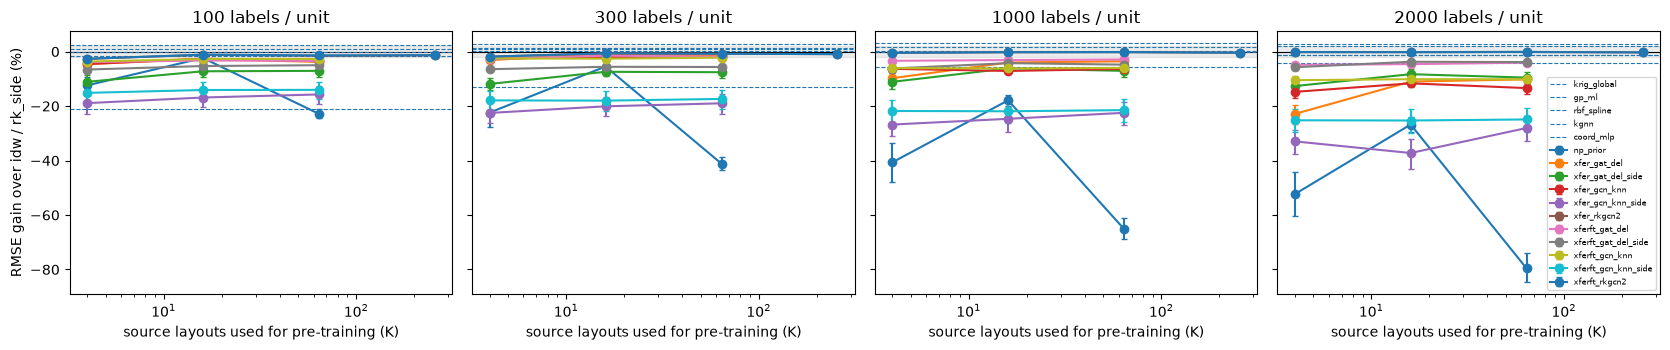

In [18]:
if x5.HAVE_TORCH:
    tabD = x5.scale_table(dD); tabD.to_csv(f"{ROOT}/D_scale_table.csv", index=False)
    display(tabD[tabD.K > 0].sort_values(["density", "kind", "tag", "K"])[["density", "method", "ref", "K", "n_clusters", "mean_gain_pct", "ci_lo", "ci_hi", "mean_gain_db", "verdict"]].round(3))
    print("classical / from-scratch reference gains (K = 0):"); display(tabD[tabD.K == 0].sort_values(["density", "method"])[["density", "method", "ref", "mean_gain_pct", "ci_lo", "ci_hi", "verdict"]].round(3))
    x5.plot_scale(tabD, f"{ROOT}/figures/fig_scale_axis.png"); plt.show()

In [19]:
# Claim rule from the frozen plan: a learned model must beat EVERY classical comparator, CI lower bound above the margin, at some (K, density).
if x5.HAVE_TORCH:
    learned = [n for n in dD.name.unique() if x5._SCALE_RE.match(n) or n in ("gcn_knn", "gat_del", "gcn_knn_side", "gat_del_side", "rk_gcn", "rk_gcn2", "coord_mlp")]
    comps = [c for c in ("idw", "rk_side", "krig_global", "gp_ml", "kgnn") if c in set(dD.name)]
    lst = [(a, b) for a in learned for b in comps if a != b]
    cD = x5.contrast_table(dD.assign(family="wall_d", split="random"), lst, by=("family", "density")); cD.to_csv(f"{ROOT}/D_vs_all_comparators.csv", index=False)
    # one row per (learned model, density): worst-case lower CI bound across comparators
    worst = cD.groupby(["A", "density"]).agg(worst_ci_lo=("ci_lo", "min"), worst_gain_pct=("mean_gain_pct", "min"), min_ci_hi=("ci_hi", "min"), n_comp=("B", "nunique")).reset_index()
    worst["clears_margin_vs_all"] = worst.worst_ci_lo > x5.MARGIN_PCT
    worst["excluded"] = worst.min_ci_hi < x5.MARGIN_PCT        # some comparator is provably NOT beaten by more than the margin -> positive claim excluded for this cell
    worst.to_csv(f"{ROOT}/D_claim_cells.csv", index=False)
    print(f"cells: {len(worst)} | positive claim excluded in {int(worst.excluded.sum())} | unresolved (neither clears nor excluded): {int((~worst.excluded & ~worst.clears_margin_vs_all).sum())}")
    display(worst.sort_values("worst_ci_lo", ascending=False).head(15).round(3))
    print("\nLEARNED MODELS THAT BEAT EVERY COMPARATOR BY > margin:", worst[worst.clears_margin_vs_all][["A", "density"]].values.tolist() or "NONE")

cells: 168 | positive claim excluded in 168 | unresolved (neither clears nor excluded): 0


,A,density,worst_ci_lo,worst_gain_pct,min_ci_hi,n_comp,clears_margin_vs_all,excluded
39,rk_gcn2,2000,-0.053,-0.019,0.000,5,False,True
38,rk_gcn2,1000,-0.099,-0.050,-0.011,5,False,True
37,rk_gcn2,300,-0.127,-0.055,-0.005,5,False,True
103,xfer64_rkgcn2,2000,-0.204,-0.127,-0.050,5,False,True
167,xferft64_rkgcn2,2000,-0.204,-0.127,-0.050,5,False,True
147,xferft4_rkgcn2,2000,-0.250,-0.162,-0.079,5,False,True
166,xferft64_rkgcn2,1000,-0.254,-0.177,-0.100,5,False,True
123,xferft16_rkgcn2,2000,-0.261,-0.193,-0.128,5,False,True
59,xfer16_rkgcn2,2000,-0.261,-0.193,-0.128,5,False,True
102,xfer64_rkgcn2,1000,-0.261,-0.181,-0.101,5,False,True



LEARNED MODELS THAT BEAT EVERY COMPARATOR BY > margin: NONE


In [20]:
# ---- D3 (v3): headroom (why classical wins, if it does) and pathological scale curves ---------------------------------------------------------------
if x5.HAVE_TORCH:
    covD = x5.covariate_table(eval_names, [WALL_D["cache_dir"]]); covD.to_csv(f"{ROOT}/D_unit_covariates.csv")
    hr = x5.headroom_table(dD.assign(family="wall_d", split="random"), covD); hr.to_csv(f"{ROOT}/D_headroom.csv", index=False)
    print("HEADROOM: the largest relative RMSE gain ANY learner could still get over the best classical method, using the variogram-nugget noise floor (rough estimate).")
    print("If it is small, 'classical wins' is a statement about the target, not about GNNs; if share_nugget_zero is large the floor is uninformative there.")
    display(hr.round(3))
    PATHO = x5.scale_pathologies(tabD); PATHO.to_csv(f"{ROOT}/D_scale_pathologies.csv", index=False)
    print("\nSCALE-CURVE PATHOLOGIES (flat at a loss across K, or worse with more source layouts):", "none" if not len(PATHO) else len(PATHO)); display(PATHO)

HEADROOM: the largest relative RMSE gain ANY learner could still get over the best classical method, using the variogram-nugget noise floor (rough estimate).
If it is small, 'classical wins' is a statement about the target, not about GNNs; if share_nugget_zero is large the floor is uninformative there.


,density,n_clusters,best_classical_rmse,floor_rmse_est,max_possible_gain_pct,ci_lo,ci_hi,share_units_at_floor,share_nugget_zero
0,100,16,3.724,0.248,92.911,85.471,98.711,0.016,0.859
1,300,16,3.244,0.248,92.067,83.627,98.547,0.031,0.859
2,1000,16,2.840,0.248,91.310,82.266,98.309,0.047,0.859
3,2000,16,2.666,0.248,91.042,81.769,98.227,0.047,0.859



SCALE-CURVE PATHOLOGIES (flat at a loss across K, or worse with more source layouts): 17


,method,density,Ks,gains_pct,flat_at_a_loss,worse_with_more_sources
0,np_prior,100,"[4, 16, 64]","[-12.42, -2.35, -22.86]",False,True
1,np_prior,300,"[4, 16, 64]","[-22.42, -5.48, -41.16]",False,True
2,np_prior,1000,"[4, 16, 64]","[-40.71, -17.9, -65.14]",False,True
3,np_prior,2000,"[4, 16, 64]","[-52.37, -26.78, -79.63]",False,True
4,xfer_gcn_knn,1000,"[4, 16, 64]","[-6.33, -7.12, -6.37]",True,False
5,xfer_gcn_knn_side,2000,"[4, 16, 64]","[-32.96, -37.24, -28.06]",False,True
6,xferft_gat_del,100,"[4, 16, 64]","[-3.88, -3.27, -3.43]",True,False
7,xferft_gat_del,1000,"[4, 16, 64]","[-3.39, -3.12, -2.9]",True,False
8,xferft_gat_del,2000,"[4, 16, 64]","[-4.86, -4.62, -4.05]",True,False
9,xferft_gat_del_side,300,"[4, 16, 64]","[-6.47, -5.58, -5.66]",True,False


In [21]:
# ---- D4 (v3): POSITIVE CONTROL. Plant y += 0.3 * std(y) * f(side covariates) (f: even / interaction terms, ~0 linear projection, SAME f on every map). -----------
#      rk_side (ridge + IDW) cannot represent f; a model pre-trained across many maps can. If no learned arm wins here, the pipeline cannot learn.
if x5.HAVE_TORCH:
    PLANT = dict(amp=0.3, seed=0); WALL_DP = {**WALL_D, "plant": PLANT}
    rk2p_paths = x5.pretrain_rk2_scale(SRC, VAL, SD["Ks3"], WALL_D_SRC, f"{ROOT}/pretrained_scale_v3", SD["rk2_base"], SD["rk2_per"], plant=PLANT, tag="rk2p")
    jobs_p = rx.base_jobs() + [dict(name="rk_side", method="rk_side", hp=dict(fset="geo_side"))] + x5.extra_jobs_v3() + x5.scale_jobs_v3(SD["Ks3"], rk2p_paths, SD["ft"])
    path_p = f"{ROOT}/D_plant.jsonl"
    x5.run_tasks5(x5.make_tasks5(eval_names, SD["pc_dens"], SD["reps"][:1], jobs_p, WALL_DP, "Dp"), path_p, N_JOBS); RUNS.append(x5.check_run(path_p, strict=not SMOKE)); dP = rc.read_results(path_p)
    learned_p = [n for n in dP.name.unique() if x5._SCALE_RE.match(n) or n == "rk_gcn2"]; comps_p = [c for c in ("idw", "rk_side", "krig_global", "kgnn") if c in set(dP.name)]
    cP = x5.contrast_table(dP.assign(family="wall_planted", split="random"), [(a, b) for a in learned_p for b in comps_p], by=("family", "density")); cP.to_csv(f"{ROOT}/D_plant_contrasts.csv", index=False)
    wP = cP.groupby(["A", "density"]).agg(worst_ci_lo=("ci_lo", "min"), worst_gain_pct=("mean_gain_pct", "min")).reset_index(); wP["clears_margin_vs_all"] = wP.worst_ci_lo > x5.MARGIN_PCT
    wP["K"] = wP.A.map(lambda n: int(x5._SCALE_RE.match(n).group(2)) if x5._SCALE_RE.match(n) else 0); wP.to_csv(f"{ROOT}/D_plant_claim_cells.csv", index=False)
    display(wP.sort_values("worst_ci_lo", ascending=False).head(12).round(3))
    kmin_ok = 16 if max(SD["Ks3"]) >= 16 else min(SD["Ks3"])
    PC_PASS = bool(wP[(wP.clears_margin_vs_all) & (wP.K >= kmin_ok)].shape[0] > 0)
    print("\nPOSITIVE CONTROL:", "PASSED (a learned arm beats every classical comparator on planted maps -> the pipeline can learn; a negative result on the real maps is meaningful)" if PC_PASS
          else "FAILED (no learned arm beats the classical ones even with a planted shared nonlinear signal -> the learning pipeline is the problem; do NOT write a negative headline)")

=== rk_gcn2 [rk2p] K=4: 16 source units, 3120 steps, validation on 32 held-out source units
    rk_gcn2 pretrain step 200/3120 train 0.2254 val(source layouts) 0.1525 best 0.1525 [11s]
    rk_gcn2 pretrain step 400/3120 train 0.1529 val(source layouts) 0.1524 best 0.1524 [23s]
    rk_gcn2 pretrain step 600/3120 train 0.1243 val(source layouts) 0.1526 best 0.1524 [34s]
    rk_gcn2 pretrain step 800/3120 train 0.1168 val(source layouts) 0.1565 best 0.1524 [46s]
    rk_gcn2 pretrain step 1000/3120 train 0.1875 val(source layouts) 0.1534 best 0.1524 [57s]
    rk_gcn2 pretrain step 1200/3120 train 0.1465 val(source layouts) 0.1564 best 0.1524 [68s]
    rk_gcn2 pretrain step 1400/3120 train 0.3028 val(source layouts) 0.1543 best 0.1524 [80s]
    rk_gcn2 pretrain step 1600/3120 train 0.1633 val(source layouts) 0.1511 best 0.1511 [91s]
    rk_gcn2 pretrain step 1800/3120 train 0.3343 val(source layouts) 0.1537 best 0.1511 [103s]
    rk_gcn2 pretrain step 2000/3120 train 0.0984 val(source layou

,A,density,worst_ci_lo,worst_gain_pct,clears_margin_vs_all,K
12,xfer64_rkgcn2,100,0.009,1.271,False,64
1,rk_gcn2,300,0.000,0.000,False,0
2,rk_gcn2,1000,-0.072,-0.023,False,0
24,xferft64_rkgcn2,100,-0.087,1.181,False,64
17,xferft16_rkgcn2,1000,-0.223,-0.047,False,16
5,xfer16_rkgcn2,1000,-0.257,-0.082,False,16
8,xfer256_rkgcn2,1000,-0.376,-0.180,False,256
20,xferft256_rkgcn2,1000,-0.380,-0.183,False,256
14,xfer64_rkgcn2,1000,-0.384,-0.224,False,64
26,xferft64_rkgcn2,1000,-0.401,-0.224,False,64



POSITIVE CONTROL: FAILED (no learned arm beats the classical ones even with a planted shared nonlinear signal -> the learning pipeline is the problem; do NOT write a negative headline)


## Part E. Missing baselines on your existing real Wi-Fi units

Adds `gp_ml` (Matern-1.5, ARD length scales + nugget by maximum marginal likelihood), `rbf_spline` (thin-plate smoothing spline, smoothing by inner 5-fold CV) and `coord_mlp` (Fourier-feature network, per-unit) next to `idw`, `krig_global`, `kgnn` on the **same units, densities and splits** as round 3 (fresh test salt and replicate ids). `rk_side`/side models are not included (UJI/SOD have no side information).

Set `E_FAMILIES` to point at your caches; names are taken from your earlier results so the units are identical.

In [22]:
E_CFG = {"uji": dict(dens=(5, 10, 20), n_test=20), "sod": dict(dens=(5, 10, 20, 60), n_test=40)}
def find_cache(name):
    for cd in CACHE_DIRS:
        if os.path.exists(os.path.join(cd, "units", name.replace("|", "__") + ".npz")): return cd
E_COVERAGE = {}
if x5.HAVE_TORCH:
    E_FAMILIES = {}
    if len(df):
        for fam, spec in E_CFG.items():
            allu = sorted(df[df.family == fam].unit.unique()) if "family" in df else []
            caches = {n: find_cache(n) for n in allu if find_cache(n)}          # v2: one cache folder PER UNIT (v1 used the first unit's folder for all -> thousands of FileNotFoundErrors)
            E_COVERAGE[fam] = len(caches) / max(len(allu), 1)
            print(f"{fam}: {len(caches)} of {len(allu)} earlier units have a cache file ({E_COVERAGE[fam]:.0%}); caches used: {sorted(set(caches.values()))}")
            if caches: E_FAMILIES[fam] = dict(names=sorted(caches), caches=caches)
    if SMOKE and not E_FAMILIES:                     # fake-data pass so the whole chain can be exercised
        E_FAMILIES = {"wall": dict(names=names_c, caches={n: WALL_C["cache_dir"] for n in names_c})}; E_CFG["wall"] = dict(dens=(20, 50), n_test=100); E_COVERAGE["wall"] = 1.0
    print({k: len(v["names"]) for k, v in E_FAMILIES.items()})


uji: 251 of 251 earlier units have a cache file (100%); caches used: ['results_conf2/cache_uji', 'results_conf3/cache_uji', 'results_ext2/cache_uji']
sod: 97 of 97 earlier units have a cache file (100%); caches used: ['results_conf2/cache_sod', 'results_conf3/cache_sod']
{'uji': 251, 'sod': 97}


In [23]:
if x5.HAVE_TORCH and E_FAMILIES:
    for fam, spec in E_FAMILIES.items():
        for split in ("random", "blocked"):
            cfg_e = dict(rx.UJI_CFG, cache_dir=None, densities=E_CFG[fam]["dens"], n_test=E_CFG[fam]["n_test"], n_rep=3, trend_policy="robust", test_salt="e5",
                         split_mode=split, block_buffer=0.0, outage_q=(0.1, 0.25), outage_abs_dbm=(), outage_min_class=8, min_unit_points=1)
            if fam == "wall": cfg_e = {**WALL_C, "split_mode": split, "test_salt": "e5"}
            jobs_e = rx.base_jobs() + x5.extra_jobs(side=False)
            if SMOKE: jobs_e = [dict(j, hp={**j.get("hp", {}), **({"steps": 20} if j.get("hp", {}).get("steps", 0) > 20 else {})}) for j in jobs_e]
            out = f"{ROOT}/smoke/{fam}/{fam}_{split}.jsonl" if SMOKE else f"{ROOT}/E/{fam}/{fam}_{split}.jsonl"
            tasks_e = []
            for cd in sorted(set(spec["caches"].values())):
                tasks_e += x5.make_tasks5([n for n in spec["names"] if spec["caches"][n] == cd], cfg_e["densities"], [600, 601, 602], jobs_e, {**cfg_e, "cache_dir": cd}, f"E|{fam}|{split}")
            x5.run_tasks5(tasks_e, out, N_JOBS); RUNS.append(x5.check_run(out, strict=not SMOKE))
    dE = x5.load_results([f"{ROOT}/smoke/*/*.jsonl" if SMOKE else f"{ROOT}/E/*/*.jsonl"])
    E_CON = [(m, "idw") for m in ("krig_global", "kgnn", "gp_ml", "rbf_spline", "coord_mlp")] + [("gp_ml", "krig_global"), ("kgnn", "gp_ml")]
    cE = x5.contrast_table(dE, E_CON, by=("family", "split", "density")); cE.to_csv(f"{ROOT}/E_baselines.csv", index=False)
    display(cE[["family", "split", "density", "A", "B", "n_clusters", "mean_gain_pct", "ci_lo", "ci_hi", "mean_gain_db", "p_holm", "verdict"]].round(3))

[run_tasks5] 2259 tasks, 2259 done, 0 to run (n_jobs=15) -> results_ext5/E/uji/uji_random.jsonl
[check_run] results_ext5/E/uji/uji_random.jsonl: 15813 rows, 0 failed (0.00%)
[run_tasks5] 2259 tasks, 2259 done, 0 to run (n_jobs=15) -> results_ext5/E/uji/uji_blocked.jsonl
[check_run] results_ext5/E/uji/uji_blocked.jsonl: 15813 rows, 0 failed (0.00%)
[run_tasks5] 1164 tasks, 1164 done, 0 to run (n_jobs=15) -> results_ext5/E/sod/sod_random.jsonl
[check_run] results_ext5/E/sod/sod_random.jsonl: 8148 rows, 0 failed (0.00%)
[run_tasks5] 1164 tasks, 1164 done, 0 to run (n_jobs=15) -> results_ext5/E/sod/sod_blocked.jsonl
[check_run] results_ext5/E/sod/sod_blocked.jsonl: 8148 rows, 0 failed (0.00%)


,family,split,density,A,B,n_clusters,mean_gain_pct,ci_lo,ci_hi,mean_gain_db,p_holm,verdict
0,sod,blocked,5,krig_global,idw,5,-7.738,-9.163,-6.236,-0.554,1.000,A worse
1,sod,blocked,10,krig_global,idw,5,-0.852,-2.075,0.371,-0.050,1.000,inconclusive
2,sod,blocked,20,krig_global,idw,5,0.675,-1.377,2.407,0.126,1.000,inconclusive
3,sod,blocked,60,krig_global,idw,5,-1.249,-2.716,0.137,0.002,1.000,inconclusive
4,sod,random,5,krig_global,idw,5,-8.198,-10.194,-6.428,-0.728,1.000,A worse
...,...,...,...,...,...,...,...,...,...,...,...,...
93,uji,blocked,10,kgnn,gp_ml,12,3.208,2.344,4.137,0.398,0.048,A better
94,uji,blocked,20,kgnn,gp_ml,12,2.285,0.893,3.605,0.311,0.253,A better
95,uji,random,5,kgnn,gp_ml,12,7.538,6.612,8.490,0.801,0.048,A better
96,uji,random,10,kgnn,gp_ml,12,5.340,4.533,6.268,0.463,0.048,A better


## Part A. The regime map (analysis; runs AFTER Part E)

For every (unit, density, split) cell we compute the relative RMSE gain of a learned method over its reference (`idw`, or `rk_side` for side-information models), and attach **target covariates computed from the unit's own map, never used by any model**:

* `noise_frac` = nugget / (nugget + partial sill) of an exponential variogram of the residual after a *quadratic surface* (the same definition for every dataset, including unknown-transmitter Wi-Fi). Near 1: fading-like noise, nobody can win. Near 0: smooth field.
* `log_lpr` = log10 of (labels x correlation-range^2 / area), i.e. how many labels fall into one correlation cell. This is the quantity that should decide whether *any* interpolator, learned or not, has something to work with.
* `los_frac`, `side_r2` (how much a linear model on the side information explains), `is_blocked`.

The regression is OLS with a **bootstrap over parents (building-floors / layouts)**, not over rows, so the CIs respect the dependence you already identified. If the regime model predicts gains on a family it was not fitted on (`lofo_r2`), the map is a finding; if not, say so.

In [24]:
# A1 (v3): reload with the Part E rows so gp_ml / rbf_spline / coord_mlp are in every table below (v2 ran this before Part E and silently lacked them)
df_all = x5.load_results(RESULT_GLOBS + [f"{ROOT}/smoke/*/*.jsonl" if SMOKE else f"{ROOT}/E/*/*.jsonl"])
df = df_all[~df_all.scenario.isin(DROP_SCENARIOS)]
miss = [m for m in ("gp_ml", "rbf_spline", "coord_mlp") if m not in set(df.name)]
assert SMOKE or not miss, f"Part E rows missing from Part A: {miss}. Run Part E first."
cov = x5.covariate_table(df.unit.unique(), CACHE_DIRS); cov.to_csv(f"{ROOT}/unit_covariates.csv"); PART_A_FINAL = True
print(len(df), "rows |", len(cov), "units with covariates | scenarios:", sorted(df.scenario.unique())[:12], "| baselines present:", [m for m in ("gp_ml", "rbf_spline", "coord_mlp") if m in set(df.name)])

303942 rows | 471 units with covariates | scenarios: ['i1_2p5', 'i2_28b', 'i3_60', 'sod', 'uji', 'wall'] | baselines present: ['gp_ml', 'rbf_spline', 'coord_mlp']


In [25]:
if len(df):
    G = [w for A, B in REG_CONTRASTS if len(w := x5.paired_gain(df, A, B))]
    gains = x5.add_density_covariates(pd.concat(G, ignore_index=True).merge(cov, left_on="unit", right_index=True, how="left"))
    gains.to_csv(f"{ROOT}/regime_gains.csv", index=False)
    ct = x5.add_abs_floor(x5.contrast_table(df, REG_CONTRASTS), MIN_DB); ct.to_csv(f"{ROOT}/regime_contrasts.csv", index=False)
    print("Practical-significance view: every contrast, per family/split/density (gain in % AND dB).")
    display(ct[["family","split","density","A","B","n_clusters","mean_gain_pct","ci_lo","ci_hi","mean_gain_db","p_holm","verdict","verdict_abs"]].round(3))
    print(ct.groupby(["A","B","verdict"]).size().unstack(fill_value=0))

Practical-significance view: every contrast, per family/split/density (gain in % AND dB).


,family,split,density,A,B,n_clusters,mean_gain_pct,ci_lo,ci_hi,mean_gain_db,p_holm,verdict,verdict_abs
0,dm_path,blocked,30,kgnn,idw,24,3.355,2.094,4.687,0.007,0.009,A better,A better (< 0.05 dB: negligible)
1,dm_path,blocked,100,kgnn,idw,24,4.057,2.813,5.351,0.007,0.004,A better,A better (< 0.05 dB: negligible)
2,dm_path,blocked,300,kgnn,idw,24,3.352,2.388,4.383,0.005,0.000,A better,A better (< 0.05 dB: negligible)
3,dm_path,blocked,30,kgnn,idw,1,NaN,NaN,NaN,0.019,1.000,too few clusters,too few clusters
4,dm_path,blocked,100,kgnn,idw,1,NaN,NaN,NaN,0.018,1.000,too few clusters,too few clusters
...,...,...,...,...,...,...,...,...,...,...,...,...,...
325,wall,blocked,50,kgnn_side,rk_side,16,-2.525,-5.651,0.509,-0.105,1.000,inconclusive,inconclusive
326,wall,blocked,100,kgnn_side,rk_side,16,-3.095,-6.304,-0.130,-0.124,1.000,A worse,A worse
327,wall,random,20,kgnn_side,rk_side,16,-2.735,-4.882,-0.624,-0.123,1.000,A worse,A worse
328,wall,random,50,kgnn_side,rk_side,16,-0.646,-3.136,2.028,-0.016,1.000,inconclusive,inconclusive


verdict                A better  A worse  equivalent (CI within +/-2%)  inconclusive  too few clusters
A             B                                                                                       
coord_mlp     idw             0       14                             0             0                 0
gat_del       idw             0       12                             0             6                12
gat_del_side  rk_side         0        9                             0             3                12
gat_del_tuned idw             0       11                             0             7                12
gcn_knn       idw             0       12                             0             6                12
gcn_knn_side  rk_side         0        9                             0             3                12
gcn_knn_tuned idw             0       11                             0             7                12
gp_ml         idw             0        7                             0   

In [26]:
# Sensitivity: v3 keeps i1_2p5 in the main tables (v2 dropped it). Show what the verdict table looks like WITHOUT it.
if len(df_all):
    ct_sens = x5.contrast_table(df_all[~df_all.scenario.isin(SENS_DROP)], REG_CONTRASTS); ct_sens.to_csv(f"{ROOT}/regime_contrasts_without_i1.csv", index=False)
    a = ct.groupby(["A", "B", "verdict"]).size().unstack(fill_value=0); b = ct_sens.groupby(["A", "B", "verdict"]).size().unstack(fill_value=0)
    print("verdict counts WITH i1_2p5 (main) minus WITHOUT: a difference > 2 cells in a column deserves a sentence in the paper (v2: 6 'A better' cells for kgnn and for krig_global lived in i1_2p5)")
    display(a.sub(b, fill_value=0).astype(int))

verdict counts WITH i1_2p5 (main) minus WITHOUT: a difference > 2 cells in a column deserves a sentence in the paper (v2: 6 'A better' cells for kgnn and for krig_global lived in i1_2p5)


,verdict,A better,A worse,equivalent (CI within +/-2%),inconclusive,too few clusters
A,B,,,,,
coord_mlp,idw,0,0,0,0,0
gat_del,idw,0,3,0,3,0
gat_del_side,rk_side,0,3,0,3,0
gat_del_tuned,idw,0,3,0,3,0
gcn_knn,idw,0,3,0,3,0
gcn_knn_side,rk_side,0,3,0,3,0
gcn_knn_tuned,idw,0,3,0,3,0
gp_ml,idw,0,0,0,0,0
kgnn,idw,6,0,0,0,0


In [27]:
if len(df):
    rows, dropped_all = [], {}
    for (A, B), w in gains.groupby(["A", "B"]):
        co, dr = x5.cluster_ols(w, "gain_pct", REGIME_X)
        if len(co): co.insert(0, "contrast", f"{A} vs {B}"); rows.append(co)
        dropped_all[f"{A} vs {B}"] = dr
    reg = pd.concat(rows, ignore_index=True) if rows else pd.DataFrame(); reg.to_csv(f"{ROOT}/regime_regression.csv", index=False)
    print("coefficients = change in % RMSE gain per +1 sd of the covariate (bootstrap over parents). Dropped covariates:", dropped_all)
    display(reg.round(3))
    print("\nLeave-one-family-out R^2 (>0: the regime map predicts gains in a dataset it never saw):")
    for (A, B), w in gains.groupby(["A", "B"]):
        r = x5.lofo_r2(w, "gain_pct", [c for c in REGIME_X if c in w and w[c].notna().mean() > .7 and w[c].nunique() > 1])
        if len(r): LOFO[f"{A} vs {B}"] = r; print(f"  {A} vs {B}"); display(r.round(3))

coefficients = change in % RMSE gain per +1 sd of the covariate (bootstrap over parents). Dropped covariates: {'coord_mlp vs idw': ['los_frac', 'side_r2'], 'gat_del vs idw': ['side_r2'], 'gat_del_side vs rk_side': [], 'gat_del_tuned vs idw': ['side_r2'], 'gcn_knn vs idw': ['side_r2'], 'gcn_knn_side vs rk_side': [], 'gcn_knn_tuned vs idw': ['side_r2'], 'gp_ml vs idw': ['los_frac', 'side_r2'], 'kgnn vs idw': ['side_r2'], 'kgnn_prior vs idw': ['side_r2'], 'kgnn_side vs rk_side': [], 'krig_global vs idw': ['side_r2'], 'rbf_spline vs idw': ['los_frac', 'side_r2']}


,contrast,term,coef_per_sd,ci_lo,ci_hi,p_boot,n_rows,n_clusters,r2_in_sample
0,coord_mlp vs idw,intercept,-10.451,-12.056,-8.719,0.000,2282,17,0.004
1,coord_mlp vs idw,noise_frac,-0.426,-1.666,1.184,0.619,2282,17,0.004
2,coord_mlp vs idw,log_lpr,1.381,0.159,2.559,0.021,2282,17,0.004
3,coord_mlp vs idw,is_blocked,0.537,-0.652,1.677,0.371,2282,17,0.004
4,gat_del vs idw,intercept,-5.536,-8.124,-2.927,0.000,1170,51,0.006
...,...,...,...,...,...,...,...,...,...
60,krig_global vs idw,is_blocked,0.101,-0.214,0.462,0.530,3020,60,0.034
61,rbf_spline vs idw,intercept,-11.695,-14.673,-8.471,0.000,2282,17,0.021
62,rbf_spline vs idw,noise_frac,-2.432,-7.823,1.633,0.356,2282,17,0.021
63,rbf_spline vs idw,log_lpr,3.989,-0.473,8.076,0.080,2282,17,0.021



Leave-one-family-out R^2 (>0: the regime map predicts gains in a dataset it never saw):
  coord_mlp vs idw


,held_out,n,r2_vs_train_mean
0,sod,776,0.007
1,uji,1506,-0.004


  gat_del vs idw


...

,held_out,n,r2_vs_train_mean
0,sod,376,0.003
1,uji,396,-0.054
2,wall,576,-0.003


  krig_global vs idw


,held_out,n,r2_vs_train_mean
0,dm_path,162,-0.035
1,sod,776,0.013
2,uji,1506,-0.016
3,wall,576,0.087


  rbf_spline vs idw


,held_out,n,r2_vs_train_mean
0,sod,776,-0.003
1,uji,1506,0.013


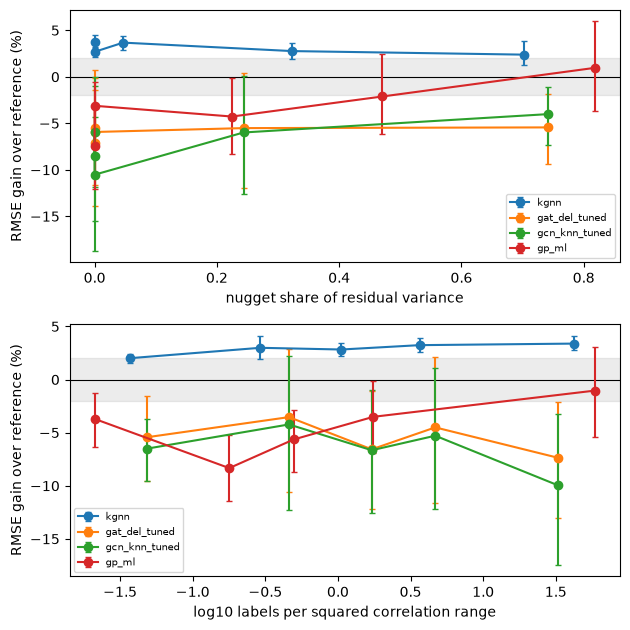

kgnn             noise_frac sign changes at x = none
kgnn             log_lpr    sign changes at x = none
gat_del_tuned    noise_frac sign changes at x = none
gat_del_tuned    log_lpr    sign changes at x = none
gcn_knn_tuned    noise_frac sign changes at x = none
gcn_knn_tuned    log_lpr    sign changes at x = none
gp_ml            noise_frac sign changes at x = [0.71]
gp_ml            log_lpr    sign changes at x = none


In [28]:
if len(df):
    heads = [m for m in ("kgnn", "gat_del_tuned", "gcn_knn_tuned", "gp_ml") if m in set(gains.A)]
    fig = x5.plot_regime(gains, heads, xs=("noise_frac", "log_lpr"), fname=f"{ROOT}/figures/fig_regime_map.png"); plt.show()
    for m in heads:
        for x in ("noise_frac", "log_lpr"):
            bt = x5.binned_gain(gains[gains.A == m], x); print(f"{m:16s} {x:10s} sign changes at x =", [round(c, 2) for c in x5.crossovers(bt)] or "none")

## Part F. More data (templates)

Step 5 of the plan: >= 12 independent environments so building-level inference has power. Two adapters that already exist in your code do most of the work.

**F1. Any Wi-Fi/BLE fingerprint CSV** (one row per reference point, one column per AP, `100` = not detected): `rmbench_ext2.build_wifi_units`. Candidates: Tampere, UTSIndoorLoc, MSLoc, Lib-/Office datasets. Check the licence and the column schema first; this cell only runs if you provide a path.

In [29]:
NEW_WIFI = dict(                        # fill in, e.g. name -> dict(csv=..., bcol=..., fcol=..., xcol=..., ycol=..., wprefix=...)
    # "tampere": dict(csv="data/tampere/train.csv", bcol="BUILDINGID", fcol="FLOOR", xcol="X", ycol="Y", wprefix="AP"),
)
if x5.HAVE_TORCH and NEW_WIFI:
    for ds, a in NEW_WIFI.items():
        raw = pd.read_csv(a["csv"]); cfg_n = dict(rx.UJI_CFG, cache_dir=f"{ROOT}/cache_{ds}", densities=(5, 10, 20), n_test=20, min_unit_points=41, trend_policy="robust")
        tab = r2.wifi_floor_table(raw, a["bcol"], a["fcol"], a["xcol"], a["ycol"], a["wprefix"]); display(tab.head())
        units, dropped = r2.build_wifi_units(raw, cfg_n, ds, a["bcol"], a["fcol"], a["xcol"], a["ycol"], a["wprefix"])
        print(ds, len(units), "units;", len(set(rx.get_unit_ext(n, cfg_n["cache_dir"])["layout"] for n in units)), "layouts")
        # then evaluate exactly like Part E with jobs rx.base_jobs() + x5.extra_jobs() and the same contrasts
else:
    print("NEW_WIFI is empty: nothing to build.")

NEW_WIFI is empty: nothing to build.


**F2. DeepMIMO with a target that is not trivially smooth** (replaces the 100%-LOS `i1_2p5` path-sum): the *narrowband channel power* target (`power_def='channel'` / `DM_HARD_CFG`), more NLOS-heavy scenarios. Needs the DeepMIMO package and network access.

In [30]:
RUN_DM = False
if RUN_DM and x5.HAVE_TORCH:
    cfg_dm = dict(rx.DM_HARD_CFG, cache_dir=f"{ROOT}/cache_dm_nb", outage_abs_dbm=(), outage_min_class=8, trend_policy="robust", test_salt="f5")
    ok_dm, dropped_dm = rx.build_dm_units(["i2_28b", "i3_60"], cfg_dm)          # add NLOS-heavy scenarios you have installed
    for n, why in dropped_dm: print("dropped:", n, why)
    by = rx.layouts_of(ok_dm, cfg_dm["cache_dir"]); print({k: len(v) for k, v in by.items()}, "-> units per layout. Descriptive only unless >= 5 layouts.")

## Part G. Claim table and the wording the data allow

Collects every verdict produced above and maps it to the wording permitted by the frozen claim rule. Nothing in this section is a new test.

In [31]:
parts = {}
for nm, p in (("A_regime", "regime_contrasts.csv"), ("C1_side", "C1_side_contrasts.csv"), ("C4_rkgcn2", "C4_rkgcn2_contrasts.csv"), ("D_vs_all", "D_vs_all_comparators.csv"), ("E_baselines", "E_baselines.csv")):
    f = f"{ROOT}/{p}"
    if os.path.exists(f): parts[nm] = pd.read_csv(f).assign(part=nm)
claims = pd.concat(parts.values(), ignore_index=True) if parts else pd.DataFrame()
WORDING = {"A better": "A improves on B (give % and dB; check it exceeds the margin before calling it practically relevant)",
           "A worse": "A is worse than B in this cell",
           "inconclusive": "the advantage was not established; per-cell numbers may be shown but not called confirmed",
           "too few clusters": "not enough independent clusters for inference; descriptive only"}
if len(claims):
    claims["allowed_wording"] = claims.verdict.map(lambda v: "A and B are equivalent within +/-%g%%" % MARGIN_PCT if str(v).startswith("equivalent") else WORDING.get(v, ""))
    claims.to_csv(f"{ROOT}/final_claims.csv", index=False)
    display(claims.groupby(["part", "verdict"]).size().unstack(fill_value=0))
    print("\nFull table:", f"{ROOT}/final_claims.csv")

verdict,A better,A worse,equivalent (CI within +/-2%),inconclusive,too few clusters
part,,,,,
A_regime,39,100,10,73,108
C1_side,2,15,3,0,0
C4_rkgcn2,0,3,13,0,0
D_vs_all,303,485,42,10,0
E_baselines,21,36,8,33,0



Full table: results_ext5/final_claims.csv


In [32]:
# Figures for the paper: regime map (Part A) and scale axis (Part D) are already saved; list what exists.
for f in sorted(glob.glob(f"{ROOT}/figures/*.png")): print(f)

results_ext5/figures/fig_regime_map.png
results_ext5/figures/fig_scale_axis.png


## Part H. Publication-readiness gate (mechanical)

This cell checks **internal validity only**: full-size run, no leaks, no silently failed jobs, priors actually applied, enough independent layouts, plan frozen. It cannot tell you whether the contribution is novel enough for a venue, and it does not replace reading the tables. It ends with the headline the data allow.

In [33]:
G = []
def chk(name, ok, detail=""):
    G.append(dict(check=name, passed=bool(ok), detail=str(detail))); print(("PASS  " if ok else "FAIL  ") + name + (f"   [{detail}]" if detail else ""))
g = lambda n, d=None: globals().get(n, d)

chk("run is full size (MODE == 'full')", MODE == "full", f"MODE={MODE}")
chk("frozen plan written before Parts C-E", os.path.exists(f"{ROOT}/prereg_ext5.json"), f"{ROOT}/prereg_ext5.json (commit it to git)")
chk("v3 amendment written (post-hoc changes are on the record)", os.path.exists(f"{ROOT}/prereg_ext5_amend_v3.json"), f"{ROOT}/prereg_ext5_amend_v3.json (commit it to git)")
chk("leak checks ran for B, B3, D, D3", {"B", "B3", "D", "D3"} <= set(LEAK), sorted(LEAK))
for k, v in LEAK.items(): chk(f"leak check {k}: identical predictions under corrupted test labels", v and all(v.values()), [n for n, o in v.items() if not o])
bad = [r["path"] for r in RUNS if r["frac"] > 0.01]
chk("every results file has <= 1% failed jobs", len(RUNS) >= 6 and not bad, f"{len(RUNS)} files checked; bad: {bad}")
chk("Part D priors applied and distinct across K / architecture (old and v3 arms)", g("SCALE_PROBS") is not None and not g("SCALE_PROBS"), "; ".join((g("SCALE_PROBS") or [])[:3]))
chk("Part D has >= 12 evaluation layouts in every cell", g("tabD") is not None and len(tabD) and tabD.n_clusters.min() >= 12, "" if g("tabD") is None else f"min clusters = {tabD.n_clusters.min()}")
chk("Part C has >= 12 layouts in every cell", g("c1") is not None and len(c1) and c1.n_clusters.min() >= 12, "" if g("c1") is None else f"min clusters = {c1.n_clusters.min()}")
chk("Part E re-evaluated >= 95% of the earlier units", bool(g("E_COVERAGE")) and all(c >= .95 for c in E_COVERAGE.values()), g("E_COVERAGE"))
chk("Part A analysed AFTER Part E (gp_ml / rbf_spline / coord_mlp rows present)", g("PART_A_FINAL") and all(m in set(df.name) for m in ("gp_ml", "rbf_spline", "coord_mlp")), "re-run the Part A cells after Part E")

# ---- C1 (v3): the strawman defence
chk("C1 (v3): rk_gcn2 with steps=0 reproduces rk_side", g("EQ") is not None and g("EQ").get("ok"), g("EQ"))
if g("c4") is not None and len(c4):
    r = c4[(c4.A == "rk_gcn2") & (c4.B == "rk_side")]
    chk("C1 (v3): rk_gcn2 is not clearly worse than rk_side at any density (else debug rk_gcn2)", len(r) and not (r.ci_hi < -MARGIN_PCT).any(), r[["density", "mean_gain_pct", "ci_lo", "ci_hi"]].round(2).values.tolist())
    r0 = c4[(c4.A == "rk_gcn") & (c4.B == "rk_side")]; print("   (informational, v2 model rk_gcn vs rk_side:", r0[["density", "mean_gain_pct"]].round(1).values.tolist(), ")")
else: chk("C1 (v3): rk_gcn2 vs rk_side computed", False, "run cell C4")

# ---- positive control: the learning pipeline must be able to win somewhere, otherwise a negative result says nothing about GNNs
chk("positive control: a learned arm beats every classical comparator on planted maps", g("PC_PASS") is True, "run cell D4" if g("PC_PASS") is None else f"PC_PASS={g('PC_PASS')}")
if g("PATHO") is not None and len(PATHO): print(f"\nWARNING: {len(PATHO)} scale curves are flat-at-a-loss or worse with more source layouts (D_scale_pathologies.csv): each needs a sentence in the paper, or a recipe fix logged as v4.")

med = np.nanmedian([v.r2_vs_train_mean.median() for v in LOFO.values()]) if LOFO else np.nan
print(f"\nregime map: median leave-one-family-out R^2 = {med:.3f} ->", "present as DESCRIPTIVE only" if not (med > 0) else "may be presented as predictive (check per-family table)")

# ---- headline allowed by the frozen claim rules
if g("worst") is not None and len(worst):
    if worst.clears_margin_vs_all.any():
        HEAD = "CANDIDATE POSITIVE: " + str(worst[worst.clears_margin_vs_all][["A", "density"]].values.tolist()) + " -> confirm on fresh evaluation layouts (new seed) before writing 'GNNs help when X'."
    elif worst.excluded.all():
        HEAD = "NEGATIVE: in every (learned model, density) cell some classical comparator is not beaten by more than the margin -> 'no tested regime shows a practically significant GNN gain'."
        if g("PC_PASS") is not True: HEAD = "VOID (positive control not passed): " + HEAD
    else:
        HEAD = f"UNRESOLVED: {int((~worst.excluded).sum())} of {len(worst)} cells neither clear nor exclude the margin -> do not write either headline; add layouts/densities or report them as unresolved."
else: HEAD = "no Part D claim table yet"
print("\nHEADLINE ALLOWED:", HEAD)
ok_all = all(x["passed"] for x in G); print("\nGATE:", "PASS (internal validity)" if ok_all else "FAIL -> do not write numbers into the paper yet")
json.dump(dict(mode=MODE, checks=G, headline=HEAD, gate_pass=ok_all, lofo_median_r2=None if med != med else float(med), positive_control=g("PC_PASS"), equivalence=g("EQ")), open(f"{ROOT}/publication_gate.json", "w"), indent=1, default=str)

PASS  run is full size (MODE == 'full')   [MODE=full]
PASS  frozen plan written before Parts C-E   [results_ext5/prereg_ext5.json (commit it to git)]
PASS  v3 amendment written (post-hoc changes are on the record)   [results_ext5/prereg_ext5_amend_v3.json (commit it to git)]
PASS  leak checks ran for B, B3, D, D3   [['B', 'B3', 'D', 'D3']]
PASS  leak check B: identical predictions under corrupted test labels
PASS  leak check B3: identical predictions under corrupted test labels
PASS  leak check D: identical predictions under corrupted test labels
PASS  leak check D3: identical predictions under corrupted test labels
PASS  every results file has <= 1% failed jobs   [13 files checked; bad: []]
PASS  Part D priors applied and distinct across K / architecture (old and v3 arms)
PASS  Part D has >= 12 evaluation layouts in every cell   [min clusters = 16]
PASS  Part C has >= 12 layouts in every cell   [min clusters = 16]
PASS  Part E re-evaluated >= 95% of the earlier units   [{'uji': 1.0, '

### How to read the outcomes (decide the paper's headline from these, mechanically)

| Outcome | Headline you may write |
|---|---|
| Part D finds a learned model clearing the margin over every comparator at some (K, density) | **"GNNs help when X"**, X = the (K, labels, covariate) region; Part A gives the covariate side of the same story. Report it with the dB gain, not only %. |
| Part D finds none, C1 shows `rk_gcn ~ rk_side`, C2 shows selection cost > 0 at low labels | **"No tested regime shows a practically significant GNN gain; failures at low labels are sample-efficiency and checkpoint-selection effects, not capacity."** |
| C1 shows `rk_gcn` also loses to `rk_side` by a clear margin | Debug before writing anything: the base or the training loop is wrong. |
| Part A's `lofo_r2` <= 0 | Do not present the regime map as predictive; present it as descriptive and say so. |
| Part E: `gp_ml` ~ `kgnn` | Your "KGNN" edge is a Matern-kriging edge; say "local kriging", not "GNN". |
| Part D: neither a clearing cell nor exclusion in every cell (`D_claim_cells.csv`) | Write neither headline. Add layouts / densities for the unresolved cells, or report them as unresolved. |
| Part D: a candidate positive cell | Confirm on fresh evaluation layouts (new seed) before writing "GNNs help when X". |
| v3: positive control (D4) fails | The pipeline cannot learn even a planted shared nonlinear signal: a negative headline is **void**. Fix pre-training (log as v4) before writing anything. |
| v3: positive control passes, Part D still shows no clearing cell | The negative result is now meaningful: the same pipeline wins when there is something to learn. |
| v3: C1 (v3) fails (`rk_gcn2(steps=0)` != `rk_side`, or `rk_gcn2` clearly worse) | Bug in the base / correction / head initialisation; debug before any other number is used. |
| v3: D3 headroom is small at the densities where classical wins | Say so: the best classical method is already near the estimated noise floor, so no learner has room (cite `D_headroom.csv`, with the caveat that the floor is a variogram estimate). |
| v3: `D_scale_pathologies.csv` is non-empty | Each listed curve (flat at a loss across K, or worse with more sources) needs a sentence or a recipe fix. |